# Project Setup

## Import libraries

In [185]:
# import libraries 
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import powerlaw as pl
from datetime import datetime

## Define global variables

In [186]:
# define global variables 
# programmatically get the current date and time
current_time = datetime.now()

# format the datetime variable
# %m = month, %d = day, %y = 2-digit year, %H = hour (24h), %M = minute
formatted_time = current_time.strftime("%m-%d-%y_%H%M")

print('Current time', current_time)
print('Formatted time', formatted_time)

# main analysis period
MAIN_START_YEAR = 2016
MAIN_END_YEAR = 2024

# replication period from Vergara-Perucich
REPLICATION_START_YEAR = 2016
REPLICATION_END_YEAR = 2021

# number of years expected in the complete main-analysis panel
EXPECTED_MAIN_YEARS = MAIN_END_YEAR - MAIN_START_YEAR + 1

# minimum total observations required before attempting a Pareto fit; this preserves the pragmatic rule used in your replication
MIN_PARETO_OBS = 5

# minimum observations required at or above xmin.
# this is a pragmatic guardrail, not a formal statistical threshold; it will later be tested using values of 2, 3, and 4
MIN_TAIL_OBS = 3

Current time 2026-08-15 15:11:33.196083
Formatted time 08-15-26_1511


## Set directories

In [187]:
# set data directories
# importing data
data_directory = "./data/"
saipe_directory = "./data/saipe/"

# exporting data 
validation_outputs = "./data/validation_outputs/" # folder for saving validation outputs
export_data = "./data/export_data/" # folder for exporting data

##  General helper functions
The following are generic helper functions used to improve readabily and reusability of code. 

### [HELPER FUNCTION]: `summarize_df()`

In [188]:
def summarize_df(df):
    '''This function displays summary information for a pandas dataframe.
    
    Args:
        df: dataframe for which to dispaly summary information
    
    '''

    num_rows = df.shape[0] # number of rows
    num_cols = df.shape[1] # number of columns
    na_sum = df.isna().sum() # count of NaN values
    na_percent = df.isna().mean() * 100 # percent of NaN values

    print("="*5, " Dataframe Summary ", "="*5)
    print(f"Cols: {num_cols}\nRows: {num_rows}\n")

    print("Descriptive Statistics", "\n", df.describe())

    print(f"\nSum of NA values\n{na_sum}\n")
    print(f"Percent of NA values\n{na_percent}")

### [HELPER FUNCTION]: `create_scatter()`

In [189]:
def create_scatter(xvalues, yvalues):
    '''This function creates a scatter plot.

    Args:
        xvalues: Series/list of values for x.
        yvalues: Series/list of values for y.
    
    '''
    plt.scatter(xvalues, yvalues)
    plt.title(f'{yvalues.name} vs. {xvalues.name}')
    plt.xlabel(f'{xvalues.name}')
    plt.ylabel(f'{yvalues.name}')
    plt.show()

# County ZHVI

In [190]:
zhvi_county_raw = pd.read_csv(data_directory + "County_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv", dtype={'StateCodeFIPS': str, 'MunicipalCodeFIPS': str})
zhvi_monthly = zhvi_county_raw.copy()
zhvi_monthly['FIPS'] = zhvi_monthly['StateCodeFIPS'] + zhvi_monthly['MunicipalCodeFIPS'] # create FIPS column
zhvi_monthly.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,StateCodeFIPS,MunicipalCodeFIPS,2000-01-31,...,2025-09-30,2025-10-31,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,FIPS
0,3101,0,Los Angeles County,county,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",06,037,213477.747479,...,883916.773570,886795.208258,890076.455189,893655.072978,895362.498190,895337.644551,893498.233890,890758.934829,888356.609933,06037
1,139,1,Cook County,county,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",17,031,152231.875544,...,323328.613001,324658.864136,326199.215954,327830.354214,329294.452674,331020.617532,332631.912914,333968.527751,334929.722712,17031
2,1090,2,Harris County,county,TX,TX,"Houston-The Woodlands-Sugar Land, TX",48,201,113626.756685,...,285568.844564,285106.406519,284871.397070,284918.541341,284769.819221,284432.808310,283821.955768,283104.733636,282112.440453,48201
3,2402,3,Maricopa County,county,AZ,AZ,"Phoenix-Mesa-Chandler, AZ",04,013,147285.047798,...,463499.240041,463063.484655,463289.307563,464080.494407,464940.778739,465619.822797,465464.974702,464452.105721,462851.196006,04013
4,2841,4,San Diego County,county,CA,CA,"San Diego-Chula Vista-Carlsbad, CA",06,073,220330.470678,...,941169.340618,941136.969646,942162.453504,944375.681251,945628.508607,946667.037565,947053.331912,946938.658258,946355.878078,06073


In [191]:
summarize_df(zhvi_monthly[['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName','State', 'Metro', 'StateCodeFIPS', 'MunicipalCodeFIPS', 'FIPS']])

=====  Dataframe Summary  =====
Cols: 10
Rows: 3072

Descriptive Statistics 
             RegionID     SizeRank
count    3072.000000  3072.000000
mean     1900.650716  1580.429688
std     12610.399140   921.684274
min        66.000000     0.000000
25%       873.750000   776.750000
50%      1670.500000  1580.500000
75%      2478.250000  2378.250000
max    698720.000000  3214.000000

Sum of NA values
RegionID                0
SizeRank                0
RegionName              0
RegionType              0
StateName               0
State                   0
Metro                1241
StateCodeFIPS           0
MunicipalCodeFIPS       0
FIPS                    0
dtype: int64

Percent of NA values
RegionID              0.000000
SizeRank              0.000000
RegionName            0.000000
RegionType            0.000000
StateName             0.000000
State                 0.000000
Metro                40.397135
StateCodeFIPS         0.000000
MunicipalCodeFIPS     0.000000
FIPS                  0.

In [192]:
zhvi_monthly.T

,0,1,2,3,4,5,6,7,8,9,...,3062,3063,3064,3065,3066,3067,3068,3069,3070,3071
RegionID,3101,139,1090,2402,2841,1286,581,2964,978,2832,...,1933,2088,1097,2518,2581,846,1648,1432,2794,2825
SizeRank,0,1,2,3,4,5,6,7,8,9,...,3195,3197,3201,3202,3203,3206,3207,3208,3212,3214
RegionName,Los Angeles County,Cook County,Harris County,Maricopa County,San Diego County,Orange County,Kings County,Miami-Dade County,Dallas County,Riverside County,...,Mineral County,Wheeler County,Hooker County,San Juan County,Treasure County,Banner County,Daggett County,Thomas County,McPherson County,Petroleum County
RegionType,county,county,county,county,county,county,county,county,county,county,...,county,county,county,county,county,county,county,county,county,county
StateName,CA,IL,TX,AZ,CA,CA,NY,FL,TX,CA,...,CO,NE,NE,CO,MT,NE,UT,NE,NE,MT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-02-28,895337.644551,331020.617532,284432.80831,465619.822797,946667.037565,1190299.835217,936487.629653,522894.00892,315564.935383,610360.625709,...,445986.989613,241718.807324,134469.905568,547119.29804,226382.229925,385853.792709,364260.769369,192656.562952,380763.042081,197841.056179
2026-03-31,893498.23389,332631.912914,283821.955768,465464.974702,947053.331912,1194767.230986,943839.346045,522797.889066,314884.129578,610452.210681,...,448703.608535,244122.2252,136367.659898,546104.945089,231942.796193,389386.960241,365890.542033,194997.540475,380966.416553,199940.277692
2026-04-30,890758.934829,333968.527751,283104.733636,464452.105721,946938.658258,1196439.20589,946923.799344,522262.933244,313887.089552,609912.512349,...,451099.453243,245184.985182,138721.834019,547973.679556,236072.715667,392778.3316,366696.225914,195523.246233,379196.687828,200902.682051
2026-05-31,888356.609933,334929.722712,282112.440453,462851.196006,946355.878078,1197199.911374,948173.11471,521999.203061,312651.68972,608810.262835,...,453224.225005,244295.756131,141269.238815,553047.809112,238361.849928,393534.631673,366895.081621,193716.834116,376954.207244,199296.70728


## Reshape county ZHVI dataset

In [193]:
# identify columns whose names can be interpreted as dates
# this prevents non-date metadata columns from being melted
date_cols = [
    col
    for col in zhvi_monthly.columns
    if pd.notna(pd.to_datetime(str(col), errors="coerce"))
]


# reshape only the monthly date columns from wide to long format
zhvi_long = zhvi_monthly.melt(
    id_vars=["FIPS", "RegionName", "State"],
    value_vars=date_cols,
    var_name="Date",
    value_name="ZHVI"
)


# convert the date field from text to pandas datetime
zhvi_long["Date"] = pd.to_datetime(
    zhvi_long["Date"],
    errors="coerce"
)


# convert ZHVI to numeric
zhvi_long["ZHVI"] = pd.to_numeric(
    zhvi_long["ZHVI"],
    errors="coerce"
)


# extract the calendar year from each monthly date
zhvi_long["Year"] = zhvi_long["Date"].dt.year


# standardize county FIPS codes as five-character strings
zhvi_long["FIPS"] = (
    zhvi_long["FIPS"]
    .astype(str)
    .str.zfill(5)
)


# define the geographic and annual grouping columns once
annual_group_cols = [
    "FIPS",
    "RegionName",
    "State",
    "Year"
]

# NOTE: This section of code was revised to create Primary and Sensitivity versions of dataframes where the mean of the ZHVI will act as the primary measure while the median of ZHVI will act as a measure for sensitivity analysis.  

# PRIMARY VERSION:
# calculate the arithmetic mean of monthly ZHVI observations within each county and year
zhvi_yearly_mean = (
    zhvi_long
    .groupby(annual_group_cols, as_index=False)
    .agg(
        ZHVI=("ZHVI", "mean"),

        # Preserve the number of nonmissing monthly observations.
        # This supports a data-quality check later.
        zhvi_months_present=("ZHVI", "count")
    )
)


# SENSITIVITY VERSION:
# calculate the annual median using the same county-year records
zhvi_yearly_median = (
    zhvi_long
    .groupby(annual_group_cols, as_index=False)
    .agg(
        ZHVI=("ZHVI", "median"),
        zhvi_months_present=("ZHVI", "count")
    )
)


# rename fields to the canonical names used elsewhere in the notebook
rename_map = {
    "RegionName": "CountyName",
    "State": "StateAbbr"
}

zhvi_yearly_mean = zhvi_yearly_mean.rename(
    columns=rename_map
)

zhvi_yearly_median = zhvi_yearly_median.rename(
    columns=rename_map
)


# restrict both versions to years supported by the SAIPE dataset
zhvi_yearly_mean = zhvi_yearly_mean.loc[
    zhvi_yearly_mean["Year"].between(2000, 2024)
].copy()

zhvi_yearly_median = zhvi_yearly_median.loc[
    zhvi_yearly_median["Year"].between(2000, 2024)
].copy()


# preserving the mean version under the existing variable name so downstream code continues to work
zhvi_yearly = zhvi_yearly_mean.copy()

### df summary

In [194]:
zhvi_yearly.info()

<class 'pandas.DataFrame'>
Index: 76800 entries, 0 to 82941
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   FIPS                 76800 non-null  str    
 1   CountyName           76800 non-null  str    
 2   StateAbbr            76800 non-null  str    
 3   Year                 76800 non-null  int32  
 4   ZHVI                 54526 non-null  float64
 5   zhvi_months_present  76800 non-null  int64  
dtypes: float64(1), int32(1), int64(1), str(3)
memory usage: 5.4 MB


In [195]:
summarize_df(zhvi_yearly)

=====  Dataframe Summary  =====
Cols: 6
Rows: 76800

Descriptive Statistics 
                Year          ZHVI  zhvi_months_present
count  76800.000000  5.452600e+04         76800.000000
mean    2012.000000  1.801106e+05             8.432826
std        7.211149  1.213950e+05             5.433558
min     2000.000000  2.884075e+04             0.000000
25%     2006.000000  1.095235e+05             0.000000
50%     2012.000000  1.480421e+05            12.000000
75%     2018.000000  2.103015e+05            12.000000
max     2024.000000  2.946959e+06            12.000000

Sum of NA values
FIPS                       0
CountyName                 0
StateAbbr                  0
Year                       0
ZHVI                   22274
zhvi_months_present        0
dtype: int64

Percent of NA values
FIPS                    0.000000
CountyName              0.000000
StateAbbr               0.000000
Year                    0.000000
ZHVI                   29.002604
zhvi_months_present     0.000000
dt

29% of ZHVI values are missing, however these may be from earlier years in the date range. This dataset currently had a date range from 2000 to 2024 to align with SAIPE Census data, however in order to replicate the results from Vergara-Perucich (2025) the date range will need to be reduced to 2016 to 2024 to align with the paper's analysis. After this reduction, the amount of missingness may be reduced. Thus, for now, the missing values will remain and will be investigated later on. 

### Missing values

In [196]:
missing_zhvi = zhvi_yearly[zhvi_yearly['ZHVI'].isna()]
missing_zhvi.head()

,FIPS,CountyName,StateAbbr,Year,ZHVI,zhvi_months_present
54,01005,Barbour County,AL,2000,NaN,0
55,01005,Barbour County,AL,2001,NaN,0
56,01005,Barbour County,AL,2002,NaN,0
57,01005,Barbour County,AL,2003,NaN,0
58,01005,Barbour County,AL,2004,NaN,0


In [197]:
print(missing_zhvi.info())
summarize_df(missing_zhvi)

<class 'pandas.DataFrame'>
Index: 22274 entries, 54 to 82929
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   FIPS                 22274 non-null  str    
 1   CountyName           22274 non-null  str    
 2   StateAbbr            22274 non-null  str    
 3   Year                 22274 non-null  int32  
 4   ZHVI                 0 non-null      float64
 5   zhvi_months_present  22274 non-null  int64  
dtypes: float64(1), int32(1), int64(1), str(3)
memory usage: 1.6 MB
None
=====  Dataframe Summary  =====
Cols: 6
Rows: 22274

Descriptive Statistics 
                Year  ZHVI  zhvi_months_present
count  22274.000000   0.0              22274.0
mean    2005.947068   NaN                  0.0
std        4.433754   NaN                  0.0
min     2000.000000   NaN                  0.0
25%     2002.000000   NaN                  0.0
50%     2005.000000   NaN                  0.0
75%     2009.000000   NaN  

In [198]:
missing_zhvi_years = set(missing_zhvi['Year'])
print(missing_zhvi_years)

{2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023}


### Monthly observations present

In [199]:
# examine how many monthly observations contribute to each annual value
monthly_coverage_summary = (
    zhvi_yearly_mean["zhvi_months_present"]
    .value_counts()
    .sort_index()
    .rename_axis("months_present")
    .rename("county_year_records")
)

monthly_coverage_summary

months_present
0     22274
1        47
2        56
3        56
4        63
5        74
6       101
7       107
8       208
9       240
10      264
11      847
12    52463
Name: county_year_records, dtype: int64

In [200]:
pct_12months_present = round(monthly_coverage_summary.iloc[-1] / zhvi_yearly.shape[0], 2) * 100
print(f"Percentage of counties with 12-months of data present: {pct_12months_present}%")

Percentage of counties with 12-months of data present: 68.0%


# U.S. Census: Small Area Income and Poverty Estimates (SAIPE) Program
The U.S. Census Bureau’s Small Area Income and Poverty Estimates program produces single-year estimates of income and poverty for all U.S. states and counties as well as estimates of school-age children in poverty for all 13,000+ school districts (source: https://www.census.gov/programs-surveys/saipe.html).

## Import census TXT files from 2000 to 2002

In [201]:
# import census files from 2000 to 2002
# fixed-width text file names
txt_files = {
    2000: "est00all.txt",
    2001: "est01all.txt",
    2002: "est02all.txt",
}

# empty list to store dataframes 
frames = []

# create dataframes via loop
for year, file in txt_files.items():
    temp = pd.read_fwf(
        saipe_directory + file, # file location and file name
        colspecs=[
            (0, 2), # FIPS state code 
            (3, 6), # FIPS county code
            (133, 139), # Median income
            (140, 146), # Median income lower bound CI
            (147, 153), # Median income upper bound CI
            (193, 238), # State/County Name
            (239, 241) # Two-letter state abbreviation
        ],
        # column names
        names=[
            "StateFIPS",
            "CountyFIPS",
            "MedianHouseholdIncome",
            "MedianIncomeLower",
            "MedianIncomeUpper",
            "CountyName",
            "StateAbbr"
        ],
        # store FIPS as string data type
        dtype={
            "StateFIPS": str,
            "CountyFIPS": str
        }
    )

    # create year column
    temp["Year"] = year

    # clean columns
    temp["CountyName"] = temp["CountyName"].str.strip()
    temp["StateAbbr"] = temp["StateAbbr"].str.strip()
    temp["FIPS"] = temp["StateFIPS"] + temp["CountyFIPS"].str.zfill(3)

    frames.append(temp)

saipe_txt = pd.concat(frames, ignore_index=True)

# include only county level data
saipe_txt = saipe_txt[saipe_txt["CountyFIPS"] != "0"].copy()

# convert datatypes
income_cols = [
    "MedianHouseholdIncome",
    "MedianIncomeLower",
    "MedianIncomeUpper"
]

for col in income_cols:
    saipe_txt[col] = pd.to_numeric(saipe_txt[col], errors="coerce")

saipe_txt.head()

,StateFIPS,CountyFIPS,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,CountyName,StateAbbr,Year,FIPS
2,01,1,42463.0,39418.0,45744.0,Autauga County,AL,2000,01001
3,01,3,41283.0,38415.0,44365.0,Baldwin County,AL,2000,01003
4,01,5,26612.0,24646.0,28736.0,Barbour County,AL,2000,01005
5,01,7,31776.0,29481.0,34250.0,Bibb County,AL,2000,01007
6,01,9,36863.0,34240.0,39687.0,Blount County,AL,2000,01009


In [202]:
saipe_txt.info()

<class 'pandas.DataFrame'>
Index: 9422 entries, 2 to 9577
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StateFIPS              9422 non-null   str    
 1   CountyFIPS             9422 non-null   str    
 2   MedianHouseholdIncome  9419 non-null   float64
 3   MedianIncomeLower      9419 non-null   float64
 4   MedianIncomeUpper      9419 non-null   float64
 5   CountyName             9422 non-null   str    
 6   StateAbbr              9422 non-null   str    
 7   Year                   9422 non-null   int64  
 8   FIPS                   9422 non-null   str    
dtypes: float64(3), int64(1), str(5)
memory usage: 974.9 KB


In [203]:
# check national level removed
saipe_txt[saipe_txt['StateFIPS'] == '00']

,StateFIPS,CountyFIPS,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,CountyName,StateAbbr,Year,FIPS


In [204]:
summarize_df(saipe_txt)

=====  Dataframe Summary  =====
Cols: 9
Rows: 9422

Descriptive Statistics 
        MedianHouseholdIncome  MedianIncomeLower  MedianIncomeUpper  \
count            9419.000000        9419.000000        9419.000000   
mean            36010.514173       33555.444421       38646.187175   
std              9203.958472        8628.415362        9821.907247   
min             15025.000000       13698.000000       16480.000000   
25%             29927.500000       27864.500000       32165.000000   
50%             34413.000000       32058.000000       36956.000000   
75%             39996.500000       37322.500000       42847.500000   
max             93927.000000       87560.000000      100758.000000   

              Year  
count  9422.000000  
mean   2001.000106  
std       0.816518  
min    2000.000000  
25%    2000.000000  
50%    2001.000000  
75%    2002.000000  
max    2002.000000  

Sum of NA values
StateFIPS                0
CountyFIPS               0
MedianHouseholdIncome    3
Medi

## Helper functions
The following helper functions are used to clean SAIPE data

### [HELPER FUNCTION]: `clean_saipe_xls()`

In [205]:
def clean_saipe_xls(df, year):
    '''Function to clean columns in dataframe. 

    Args: 
        df: Dataframe to be cleaned.
        year: Column year to be cleaned.
    
    Returns:
        Cleaned dataframe.
    '''

    # standardize column names
    df.columns = (
        df.columns
          .astype(str)
          .str.strip()
          .str.replace("\n", " ", regex=False)
          .str.replace(r"\s+", " ", regex=True)
    )

    # rename columns to consistent names
    rename_map = {
        "State FIPS": "StateFIPS",
        "State FIPS Code": "StateFIPS",
        "County FIPS": "CountyFIPS",
        "County FIPS Code": "CountyFIPS",
        "Postal Code": "StateAbbr",
        "Postal": "StateAbbr",
        "Name": "CountyName",
        "Area Name": "CountyName",
        "Median Household Income": "MedianHouseholdIncome",
        "90% CI Lower Bound.6": "MedianIncomeLower",
        "90% CI Upper Bound.6": "MedianIncomeUpper",
    }

    df = df.rename(columns={c: rename_map.get(c, c) for c in df.columns})

    # remove fully blank rows
    df = df.dropna(how="all")

    # keep only needed canonical columns
    wanted = [
        "StateFIPS",
        "CountyFIPS",
        "CountyName",
        "StateAbbr",
        "MedianHouseholdIncome",
        "MedianIncomeLower",
        "MedianIncomeUpper",
    ]

    df = df[[c for c in wanted if c in df.columns]].copy()

    # Ddop rows missing the identifiers
    df = df.dropna(subset=["StateFIPS", "CountyFIPS"])

    # clean FIPS codes
    df["StateFIPS"] = df["StateFIPS"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(2) # add leading zeros
    df["CountyFIPS"] = df["CountyFIPS"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(3) # add leading zeros

    # keep county-level records only
    df = df[df["CountyFIPS"] != "000"].copy()

    # Create full county FIPS
    df["FIPS"] = df["StateFIPS"] + df["CountyFIPS"]
    df["Year"] = year

    # clean text columns
    if "CountyName" in df.columns:
        df["CountyName"] = df["CountyName"].astype(str).str.strip()

    if "StateAbbr" in df.columns:
        df["StateAbbr"] = df["StateAbbr"].astype(str).str.strip()

    # convert income fields to numeric
    income_cols = ["MedianHouseholdIncome", "MedianIncomeLower", "MedianIncomeUpper"]
    for col in income_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

### [HELPER FUNCTION]: `rows_to_skip()`

In [206]:
def rows_to_skip(year):
    '''Function to skip rows for specific years in xls files. Certain years in SAIPE data files are formatted differently. This function helps determine how many rows to skip.

    Args:
        year: Value for year
    
    Returns:
        Value for number of rows to skip when importing XLS file.

    Raises:
        ValueError: If unexpected year is provided.
    '''
    
    if 2003 <= year <= 2004:
        return 1 # skip 1 row for years between 2003 and 2004
    elif 2005 <= year <= 2012:
        return 2 # skip 2 rows for years between 2005 and 2012
    elif 2013 <= year <= 2024:
        return 3 # skip 3 rows for years between 2013 and 2014
    else:
        raise ValueError(f"Unexpected year: {year}") # raises error if a year is provided that is not included in the above ranges

## Import census XLS files from 2003 to 2024

In [207]:
# import census from 2003 to 2024
# xls file names
xls_files = {
    year: f"est{str(year)[2:]}all.xls" for year in range(2003, 2025)
}

# empty list to store dataframes 
frames = []

# loop through each xls file
for year, file in xls_files.items():
    temp = pd.read_excel(
        saipe_directory + file,
        usecols="A:D,W:Y",
        skiprows=rows_to_skip(year),
    )

    temp = clean_saipe_xls(temp, year)

    frames.append(temp)

saipe_xls = pd.concat(frames, ignore_index=True)

saipe_xls.head()

,StateFIPS,CountyFIPS,CountyName,StateAbbr,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,FIPS,Year
0,01,001,Autauga County,AL,44241.0,41547.0,47109.0,01001,2003
1,01,003,Baldwin County,AL,41961.0,39479.0,44600.0,01003,2003
2,01,005,Barbour County,AL,26062.0,24432.0,27801.0,01005,2003
3,01,007,Bibb County,AL,32924.0,30916.0,35062.0,01007,2003
4,01,009,Blount County,AL,37758.0,35473.0,40191.0,01009,2003


In [208]:
saipe_xls.info()

<class 'pandas.DataFrame'>
RangeIndex: 69132 entries, 0 to 69131
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StateFIPS              69132 non-null  str    
 1   CountyFIPS             69132 non-null  str    
 2   CountyName             69132 non-null  str    
 3   StateAbbr              69132 non-null  str    
 4   MedianHouseholdIncome  69111 non-null  float64
 5   MedianIncomeLower      69111 non-null  float64
 6   MedianIncomeUpper      69111 non-null  float64
 7   FIPS                   69132 non-null  str    
 8   Year                   69132 non-null  int64  
dtypes: float64(3), int64(1), str(5)
memory usage: 6.5 MB


In [209]:
# check national level removed
saipe_xls[saipe_xls['CountyName'] == "US"]

,StateFIPS,CountyFIPS,CountyName,StateAbbr,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,FIPS,Year


In [210]:
summarize_df(saipe_xls)

=====  Dataframe Summary  =====
Cols: 9
Rows: 69132

Descriptive Statistics 
        MedianHouseholdIncome  MedianIncomeLower  MedianIncomeUpper  \
count           69111.000000       69111.000000       69111.000000   
mean            49189.252232       45307.860485       53084.271129   
std             15606.426824       14753.977817       16575.356815   
min                 0.000000           0.000000           0.000000   
25%             38213.500000       35030.000000       41353.500000   
50%             46233.000000       42421.000000       49952.000000   
75%             56797.000000       52155.500000       61523.000000   
max            177457.000000      168768.000000      186146.000000   

               Year  
count  69132.000000  
mean    2013.501461  
std        6.344325  
min     2003.000000  
25%     2008.000000  
50%     2014.000000  
75%     2019.000000  
max     2024.000000  

Sum of NA values
StateFIPS                 0
CountyFIPS                0
CountyName         

## Merge SAIPE dataframes

### Standardize SAIPE dataframes

In [211]:
# align the two SAIPE dfs
saipe_cols = [
    "FIPS",
    "CountyName",
    "StateAbbr",
    "Year",
    "MedianHouseholdIncome",
    "MedianIncomeLower",
    "MedianIncomeUpper"
]

saipe_txt_clean = saipe_txt[saipe_cols].copy()
saipe_xls_clean = saipe_xls[saipe_cols].copy()

In [212]:
# create yearly SAIPE  df
saipe_yearly = pd.concat(
    [saipe_txt_clean, saipe_xls_clean],
    ignore_index=True
)

In [213]:
# standardize merge keys
saipe_yearly["FIPS"] = saipe_yearly["FIPS"].astype(str).str.zfill(5)

In [214]:
# remove duplicate columns for county/state names
saipe_merge = saipe_yearly[
    [
        "FIPS",
        "Year",
        "MedianHouseholdIncome",
        "MedianIncomeLower",
        "MedianIncomeUpper"
    ]
].copy()

In [215]:
saipe_merge.info()

<class 'pandas.DataFrame'>
RangeIndex: 78554 entries, 0 to 78553
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   FIPS                   78554 non-null  str    
 1   Year                   78554 non-null  int64  
 2   MedianHouseholdIncome  78530 non-null  float64
 3   MedianIncomeLower      78530 non-null  float64
 4   MedianIncomeUpper      78530 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 3.4 MB


### Summary of merged dataframe

In [216]:
summarize_df(saipe_merge)

=====  Dataframe Summary  =====
Cols: 5
Rows: 78554

Descriptive Statistics 
                Year  MedianHouseholdIncome  MedianIncomeLower  \
count  78554.000000           78530.000000       78530.000000   
mean    2012.002011           47608.575627       43898.258971   
std        7.211076           15583.319114       14665.567839   
min     2000.000000               0.000000           0.000000   
25%     2006.000000           36591.000000       33623.000000   
50%     2012.000000           44522.000000       40876.000000   
75%     2018.000000           55267.750000       50755.000000   
max     2024.000000          177457.000000      168768.000000   

       MedianIncomeUpper  
count       78530.000000  
mean        51352.546785  
std         16594.061493  
min             0.000000  
25%         39560.000000  
50%         48110.500000  
75%         59768.750000  
max        186146.000000  

Sum of NA values
FIPS                      0
Year                      0
MedianHouseholdInco

### Missing values in SAIPE datasets
Missing income values from SAIPE are minimal, so county-year observations missing median household income will be excluded from analysis.

## Merge ZHVI with SAIPE

### [HELPER FUNCTION]: `merge_housing_income()`

In [217]:
def merge_housing_income(zhvi_df, income_df):
    '''This function merges annual county ZHVI with annual county income.

    Args:
        zhvi_df: Dataframe with county ZHVI values.
        income_df: Dataframe with income values.

    Returns:
        Merged dataframe on FIPS and Year values.
    '''
    # copy inputs so the original df's are not changed
    zhvi = zhvi_df.copy()
    income = income_df.copy()

    # standardize FIPS in both inputs before merging
    zhvi["FIPS"] = zhvi["FIPS"].astype(str).str.zfill(5)
    income["FIPS"] = income["FIPS"].astype(str).str.zfill(5)

    # ensure Year is numeric in both inputs
    zhvi["Year"] = pd.to_numeric(
        zhvi["Year"],
        errors="raise"
    ).astype(int)

    income["Year"] = pd.to_numeric(
        income["Year"],
        errors="raise"
    ).astype(int)

    # merge county and year
    # validate="one_to_one" raises an error if either dataset contains duplicate county-year records
    merged = zhvi.merge(
        income,
        on=["FIPS", "Year"],
        how="left",
        validate="one_to_one"
    )

    # preserve whether each source variable was originally missing
    merged["ZHVI_missing_original"] = merged["ZHVI"].isna()
    merged["Income_missing_original"] = (
        merged["MedianHouseholdIncome"].isna()
    )

    return merged

In [218]:
# merge the mean-ZHVI version
housing_df_mean = merge_housing_income(zhvi_yearly_mean, saipe_merge)

# merge the median-ZHVI sensitivity version
housing_df_median = merge_housing_income(zhvi_yearly_median, saipe_merge)

# keep the annual-mean version as the primary dataset
housing_df = housing_df_mean.copy()
housing_df.head()

,FIPS,CountyName,StateAbbr,Year,ZHVI,zhvi_months_present,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,ZHVI_missing_original,Income_missing_original
0,01001,Autauga County,AL,2000,124296.447092,12,42463.0,39418.0,45744.0,False,False
1,01001,Autauga County,AL,2001,129162.040935,12,42183.0,39405.0,45156.0,False,False
2,01001,Autauga County,AL,2002,131018.098877,12,42841.0,40010.0,45872.0,False,False
3,01001,Autauga County,AL,2003,135381.759488,12,44241.0,41547.0,47109.0,False,False
4,01001,Autauga County,AL,2004,140201.076676,12,45379.0,42625.0,48310.0,False,False


### Summary

In [219]:
housing_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76800 entries, 0 to 76799
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FIPS                     76800 non-null  str    
 1   CountyName               76800 non-null  str    
 2   StateAbbr                76800 non-null  str    
 3   Year                     76800 non-null  int64  
 4   ZHVI                     54526 non-null  float64
 5   zhvi_months_present      76800 non-null  int64  
 6   MedianHouseholdIncome    76752 non-null  float64
 7   MedianIncomeLower        76752 non-null  float64
 8   MedianIncomeUpper        76752 non-null  float64
 9   ZHVI_missing_original    76800 non-null  bool   
 10  Income_missing_original  76800 non-null  bool   
dtypes: bool(2), float64(4), int64(2), str(3)
memory usage: 7.0 MB


In [220]:
summarize_df(housing_df)

=====  Dataframe Summary  =====
Cols: 11
Rows: 76800

Descriptive Statistics 
                Year          ZHVI  zhvi_months_present  MedianHouseholdIncome  \
count  76800.000000  5.452600e+04         76800.000000           76752.000000   
mean    2012.000000  1.801106e+05             8.432826           47673.446073   
std        7.211149  1.213950e+05             5.433558           15549.869768   
min     2000.000000  2.884075e+04             0.000000           16435.000000   
25%     2006.000000  1.095235e+05             0.000000           36684.000000   
50%     2012.000000  1.480421e+05            12.000000           44590.500000   
75%     2018.000000  2.103015e+05            12.000000           55297.250000   
max     2024.000000  2.946959e+06            12.000000          177457.000000   

       MedianIncomeLower  MedianIncomeUpper  
count       76752.000000       76752.000000  
mean        43979.154745       51401.382622  
std         14649.468066       16542.006659  
min    

## Missing values

In [221]:
missing_by_year = (
    housing_df
        .groupby("Year")
        .agg(
            total_rows=("FIPS", "size"),
            unique_counties=("FIPS", "nunique"),
            missing_zhvi=("ZHVI", lambda s: s.isna().sum()),
            missing_zhvi_pct=("ZHVI", lambda s: s.isna().mean() * 100),
            missing_income=("MedianHouseholdIncome", lambda s: s.isna().sum()),
            missing_income_pct=("MedianHouseholdIncome", lambda s: s.isna().mean() * 100)
        )
        .reset_index()
)

missing_by_year

,Year,total_rows,unique_counties,missing_zhvi,missing_zhvi_pct,missing_income,missing_income_pct
0,2000,3072,3072,2018,65.690104,3,0.097656
1,2001,3072,3072,1977,64.355469,2,0.065104
2,2002,3072,3072,1936,63.020833,2,0.065104
3,2003,3072,3072,1878,61.132812,2,0.065104
4,2004,3072,3072,1835,59.733073,2,0.065104
5,2005,3072,3072,1786,58.138021,2,0.065104
6,2006,3072,3072,1756,57.161458,2,0.065104
7,2007,3072,3072,1702,55.403646,2,0.065104
8,2008,3072,3072,1632,53.125000,2,0.065104
9,2009,3072,3072,1057,34.407552,0,0.000000


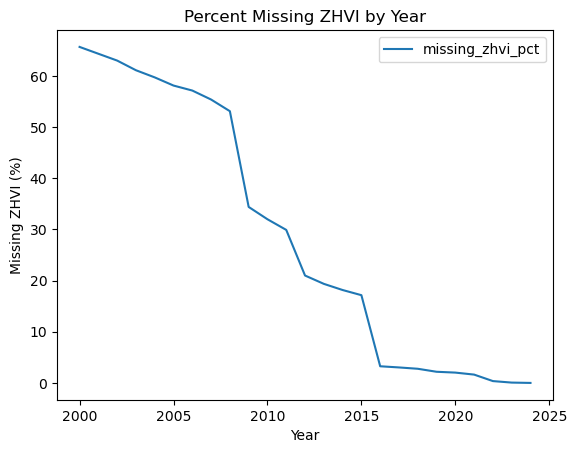

In [222]:
missing_by_year.plot(
    x="Year",
    y="missing_zhvi_pct",
    kind="line",
    title="Percent Missing ZHVI by Year"
)

plt.ylabel("Missing ZHVI (%)")
plt.show()

### Conlusion
ZHVI missingness is more substantial than SAIPE income data. And ZHVI missingness is more common among earlier years in the dataset (primarily 2000-2016). Therefore, the primary dataset used will include observed county-year records with both ZHVI adn median household income available. Further, the initial analysis will attempt to replicate the findings of Vergara-Perucich (2025) a date range of 2016 to 2021 will be used align with their analysis (p. 5). 

# Create primary datasets

## [HELPER FUNCTION]: `create_analysis_panel()`

In [223]:
def create_analysis_panel( merged_df, start_year, end_year):
    '''This function creates a clean county-year analysis panel and calculates PIR.

    Args:
        merged_df: Merged dataframe containing ZHVI and income values. 
        start_year: Beginning year of analysis. 
        end_year: End year of analysis.

    Returns: 
        Clean dataframe for county-year analysis with calculated PIR.

    Asserts: 
        Confirms no duplicate county entries.
    '''
    # restrict the dataset to the requested analysis period
    panel = merged_df.loc[
        merged_df["Year"].between(start_year, end_year)
    ].copy()

    # remove records missing either input needed to calculate PIR
    panel = panel.dropna(
        subset=["ZHVI", "MedianHouseholdIncome"]
    ).copy()

    # remove impossible or invalid nonpositive values
    panel = panel.loc[
        (panel["ZHVI"] > 0) & (panel["MedianHouseholdIncome"] > 0)
    ].copy()

    # calculate price-to-income ratio
    panel["PIR"] = (
        panel["ZHVI"] / panel["MedianHouseholdIncome"]
    )

    # verify that each county has no more than one record per year
    duplicate_count = panel.duplicated(subset=["FIPS", "Year"]).sum()

    assert duplicate_count == 0, (
        f"Found {duplicate_count} duplicate county-year records."
    )

    # sort for all subsequent time-based operations
    panel = (
        panel
        .sort_values(["FIPS", "Year"])
        .reset_index(drop=True)
    )

    return panel

## Create housing analysis dataframes

In [224]:
# replication dataset using the annual-mean ZHVI
housing_analysis = create_analysis_panel(
    housing_df_mean,
    REPLICATION_START_YEAR,
    REPLICATION_END_YEAR
)

# main 2016–2024 dataset using annual-mean ZHVI
housing_analysis_ext = create_analysis_panel(
    housing_df_mean,
    MAIN_START_YEAR,
    MAIN_END_YEAR
)

## Confirm df creation
Create summary of df to confirm the following: 
- Date range
- Missing values 
- Number of observations 

In [225]:
summarize_df(housing_analysis)

=====  Dataframe Summary  =====
Cols: 12
Rows: 17973

Descriptive Statistics 
                Year          ZHVI  zhvi_months_present  MedianHouseholdIncome  \
count  17973.000000  1.797300e+04         17973.000000           17973.000000   
mean    2018.509820  1.834373e+05            11.969565           54505.186558   
std        1.707942  1.171314e+05             0.216495           14523.772561   
min     2016.000000  4.393307e+04             1.000000           22045.000000   
25%     2017.000000  1.173816e+05            12.000000           44842.000000   
50%     2019.000000  1.531424e+05            12.000000           52019.000000   
75%     2020.000000  2.126356e+05            12.000000           61037.000000   
max     2021.000000  2.250951e+06            12.000000          160305.000000   

       MedianIncomeLower  MedianIncomeUpper           PIR  
count       17973.000000       17973.000000  17973.000000  
mean        49871.322484       59139.050632      3.258394  
std        

- Date range confirmed; between 2016 and 2021
- Missing values have been dropped 
- Number of observations is 17973

# EDA: Housing Data

## Summary

In [226]:
housing_analysis

,FIPS,CountyName,StateAbbr,Year,ZHVI,zhvi_months_present,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,ZHVI_missing_original,Income_missing_original,PIR
0,01001,Autauga County,AL,2016,167815.551701,12,54487.0,50886.0,58088.0,False,False,3.079919
1,01001,Autauga County,AL,2017,170193.486007,12,58343.0,52121.0,64565.0,False,False,2.917119
2,01001,Autauga County,AL,2018,174055.653961,12,59338.0,53628.0,65048.0,False,False,2.933292
3,01001,Autauga County,AL,2019,180888.952145,12,58233.0,52517.0,63949.0,False,False,3.106296
4,01001,Autauga County,AL,2020,191420.415687,12,67565.0,59132.0,75998.0,False,False,2.833130
...,...,...,...,...,...,...,...,...,...,...,...,...
17968,56045,Weston County,WY,2017,174261.754394,12,56214.0,50250.0,62178.0,False,False,3.099971
17969,56045,Weston County,WY,2018,174140.699135,12,54319.0,48315.0,60323.0,False,False,3.205889
17970,56045,Weston County,WY,2019,176442.298919,12,59410.0,52275.0,66545.0,False,False,2.969909
17971,56045,Weston County,WY,2020,183169.137636,12,58901.0,50079.0,67723.0,False,False,3.109780


In [227]:
housing_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 17973 entries, 0 to 17972
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FIPS                     17973 non-null  str    
 1   CountyName               17973 non-null  str    
 2   StateAbbr                17973 non-null  str    
 3   Year                     17973 non-null  int64  
 4   ZHVI                     17973 non-null  float64
 5   zhvi_months_present      17973 non-null  int64  
 6   MedianHouseholdIncome    17973 non-null  float64
 7   MedianIncomeLower        17973 non-null  float64
 8   MedianIncomeUpper        17973 non-null  float64
 9   ZHVI_missing_original    17973 non-null  bool   
 10  Income_missing_original  17973 non-null  bool   
 11  PIR                      17973 non-null  float64
dtypes: bool(2), float64(5), int64(2), str(3)
memory usage: 1.8 MB


In [228]:
summarize_df(housing_analysis)

=====  Dataframe Summary  =====
Cols: 12
Rows: 17973

Descriptive Statistics 
                Year          ZHVI  zhvi_months_present  MedianHouseholdIncome  \
count  17973.000000  1.797300e+04         17973.000000           17973.000000   
mean    2018.509820  1.834373e+05            11.969565           54505.186558   
std        1.707942  1.171314e+05             0.216495           14523.772561   
min     2016.000000  4.393307e+04             1.000000           22045.000000   
25%     2017.000000  1.173816e+05            12.000000           44842.000000   
50%     2019.000000  1.531424e+05            12.000000           52019.000000   
75%     2020.000000  2.126356e+05            12.000000           61037.000000   
max     2021.000000  2.250951e+06            12.000000          160305.000000   

       MedianIncomeLower  MedianIncomeUpper           PIR  
count       17973.000000       17973.000000  17973.000000  
mean        49871.322484       59139.050632      3.258394  
std        

### Confirm State and County counts

In [229]:
states = set(housing_analysis['StateAbbr'].value_counts().index)
print(f"Number of states: {len(states)}")
print(f"States present in data:\n{states}")

Number of states: 51
States present in data:
{'MS', 'TX', 'NM', 'UT', 'MD', 'HI', 'CO', 'NE', 'NJ', 'ME', 'IN', 'WY', 'IL', 'AZ', 'SC', 'SD', 'NY', 'LA', 'VT', 'MT', 'ID', 'DE', 'NH', 'MA', 'OR', 'RI', 'ND', 'MI', 'KS', 'CT', 'OK', 'AL', 'IA', 'TN', 'OH', 'KY', 'FL', 'AR', 'WV', 'WI', 'NV', 'PA', 'CA', 'NC', 'MO', 'DC', 'MN', 'VA', 'GA', 'AK', 'WA'}


In [230]:
counties = set(housing_analysis['FIPS'].value_counts().index)
print(f"Number of counties: {len(counties)}")

Number of counties: 3022


In [231]:
# PIR count distribution
pir_count_distribution = pd.DataFrame(
    housing_analysis
        .groupby("FIPS")["PIR"]
        .count()
        .value_counts()
        .sort_index(ascending=False)
        .rename_axis("pir_observations_per_county")
        .rename("number_of_counties")
)

pir_count_distribution

,number_of_counties
pir_observations_per_county,
6,2971
5,7
4,9
3,18
2,5
1,12


The above confirms that there are 2971 counties that have at least 6 observations for PIR. This is important for fitting the data to a Pareto distribution because too few observations will produce a poorly fit model. 

## Scatter plots

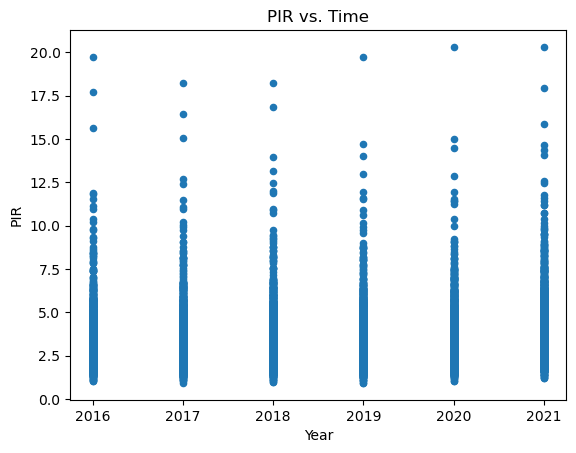

In [232]:
housing_analysis.plot.scatter(x='Year', y='PIR')
plt.title("PIR vs. Time")

plt.show()

### Observations 
- ZHVI and income increase over time
  - However, the rate of growth should be investigated to see if housing prices are outpacing income growth
- PIR flunctuates over time with peaks around 2005, 2005, and 2022-23
  - The recommended house price is 3 to 5 times annual income so any PIR above 5 should be investigated because these values exceed the recommended guidelines. 

## Histograms

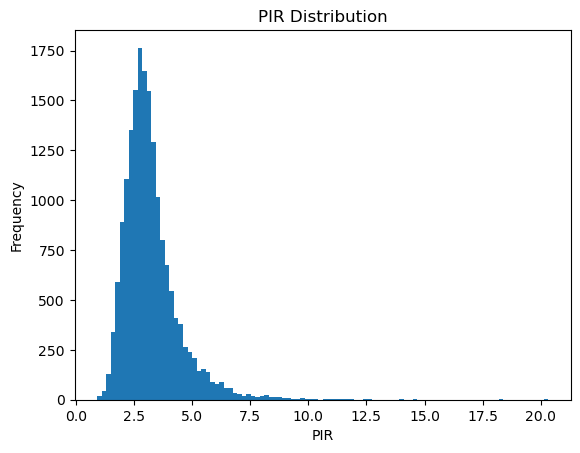

In [233]:
housing_analysis["PIR"].plot.hist(bins=100)
plt.xlabel("PIR")
plt.title("PIR Distribution")
plt.show()

### Observations
All graphs exhibit a right skewness. This is to be expected since there are outliers within housing prices and incomes. In terms of model choice, this skewness will need to be taken into account. 

# Replication Analysis 
The following is an attempt to replicate the results described in the paper "Housing Affordability in the United States: Price-to-Income Ratio by Pareto Distribution" by Francisco Vergara-Perucich published Geographies in October of 2025.

## Analysis helper functions

### [HELPER FUNCTION]: `fit_pareto_county()`

In [234]:
def fit_pareto_county(county):
    '''This function fits county PIR values to Pareto distribution using the powerlaw library.

    Args:
        county: Dataframe row with county data (series like)

    Returns:
        Pandas series with Pareto distribution parameter values:
            alpha: Shape parameter for how quickly the tail drops off. Lower value indicates higher probability of extreme values.
            xmin: Scale factor or minimum possible x-value.
            ks_distance: Kolmogrov-Smirnov distance; used to determine agreement between fitted distrubtion and observed data. Lower is better.
            n_obs: Number of observations.
            n_tail: Number of tail observations.
            tail_share: Ratio of tail observations to total observations.
            R_log: log-likelihood ratio for the lognormal distriubtion. Used to compare fit of Pareto distribution. A positive value means the Pareto distribution fits better; negative means the alternative wins. 
            p_log: p-value for the lognormal distriubtion. Used to compare fit of Pareto distribution. tells you if the difference between the two models is statistically significant. If the p-value is greater than 0.05, the direction of R is not statistically significant. It means the library cannot definitively tell which distribution fits better.
            R_exp: log-likelihood ratio for the exponential distriubtion. Used to compare fit of Pareto distribution. A positive value means the Pareto distribution fits better; negative means the alternative wins. 
            p_exp: p-value for the exponential distriubtion. Used to compare fit of Pareto distribution. tells you if the difference between the two models is statistically significant. If the p-value is greater than 0.05, the direction of R is not statistically significant. It means the library cannot definitively tell which distribution fits better.
    '''
    pir = (
        county['PIR']
        .replace([np.inf, -np.inf], np.nan) # replace infinity values with NaN
        .dropna() # powerlaw.Fit() cannot be used with NA values
    )
    pir = pir[pir > 0] # power distributions must have values greater than 0
    n_obs = len(pir)

    # check sample size
    if n_obs < 5: # more than 5 values are ideal for power law distributions
        return pd.Series({ # return NaN values for sample size below threshold
            "alpha": np.nan,
            "xmin": np.nan,
            "ks_distance": np.nan,
            "n_obs": n_obs,
            "n_tail": np.nan,
            "tail_share": np.nan,
            "R_log": np.nan,
            "p_log": np.nan,
            "R_exp": np.nan,
            "p_exp": np.nan
        })
    
    # fit PIR to power law (Pareto) distribution
    fit = pl.Fit(
        pir, 
        fit_method='Likelihood', # use Maximum Liklihood Estimate to estimate alpha
        xmin_distance="D", # use Kolmogorov-Smirnov distance to estimate xmin (aligning with Vergara-Perucich paper)
        discrete=False,
        verbose=False)

    xmin = fit.power_law.xmin
    n_tail = int((pir >= xmin).sum())
    R_log, p_log = fit.distribution_compare("power_law", "lognormal")
    R_exp, p_exp = fit.distribution_compare("power_law", "exponential")

    return pd.Series({ # return series with parameter values
        "alpha": fit.power_law.alpha, 
        "xmin": xmin,
        "ks_distance": fit.power_law.D,
        "n_obs": n_obs,  
        "n_tail": n_tail, 
        "tail_share": n_tail / n_obs,
        "R_log": R_log,
        "p_log": p_log,
        "R_exp": R_exp,
        "p_exp": p_exp
    })

### [HELPER FUNCTION]: `normalize_values()`

In [235]:
def normalize_values(df, col):
    '''This function normalizes values.'''
    df[f'{col}_norm'] = ((df[col] - df[col].min()) / (df[col].max() - df[col].min()))

### [HELPER FUNCTION]: `calc_pareto_composite()`
Vergara-Perucich (2025) takes the average of the normalized values for `alpha` and `xmin` to create a single housing price indicator (p. 6). The following helper function calculates this affordability metric and stores it in the specified dataframe. 

In [236]:
def calc_pareto_composite(df):
    '''This function calculates the affordabiltiy metric based on Vergara-Perucich methodology. Modifies original dataframe.
    '''
    df['pareto_composite'] = (df['alpha_norm'] + df['xmin_norm']) / 2

## Calculate results

In [237]:
# fit each county's PIR data to Pareto distribution
vp_results = (
    housing_analysis
        .groupby("FIPS") # group by county FIPS ID
        .apply(fit_pareto_county) # fit to Pareto distribution
        .reset_index()
)

vp_results

/Users/anthonynanfito/miniconda3/envs/ds314/lib/python3.14/site-packages/powerlaw.py:699: RuntimeWarning: invalid value encountered in divide
  (CDF_diff**2) /
/Users/anthonynanfito/miniconda3/envs/ds314/lib/python3.14/site-packages/powerlaw.py:1605: RuntimeWarning: invalid value encountered in divide
  CDF = CDF/norm
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
'nan' in fit cumulative distribution values.
Likely unde

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp
0,01001,18.679659,2.833130,0.271593,6.0,6.0,1.000000,-0.676005,0.546434,-0.094233,0.203398
1,01003,13.851284,3.675297,0.143288,6.0,6.0,1.000000,-0.117551,0.016587,0.033217,0.802372
2,01005,27.548005,3.273150,0.168018,6.0,5.0,0.833333,-0.202711,0.000550,0.055793,0.303667
3,01007,17.851880,3.270382,0.142972,6.0,6.0,1.000000,-0.376600,0.060537,0.118737,0.172987
4,01009,26.285446,3.101743,0.131068,6.0,6.0,1.000000,-1.844690,0.000008,0.032602,0.583183
...,...,...,...,...,...,...,...,...,...,...,...
3017,56037,17.246326,2.871959,0.232561,6.0,5.0,0.833333,-0.154138,0.746509,-0.052782,0.527860
3018,56039,10.453426,10.718566,0.158160,6.0,6.0,1.000000,-0.625994,0.281396,0.048945,0.787981
3019,56041,16.377782,2.758511,0.130223,6.0,6.0,1.000000,-0.272221,0.005935,0.057830,0.588256
3020,56043,31.837355,2.897437,0.168071,6.0,5.0,0.833333,-0.028706,0.885357,-0.013715,0.783829


## Normalize `alpha` and `xmin`, calculate affordability metric

In [238]:
# normalize alpha and xmin values 
normalize_values(vp_results, 'alpha')
normalize_values(vp_results, 'xmin')

# calculate pareto_composite metric 
calc_pareto_composite(vp_results)

# display updated dataframe
vp_results

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite
0,01001,18.679659,2.833130,0.271593,6.0,6.0,1.000000,-0.676005,0.546434,-0.094233,0.203398,0.000301,0.101399,0.050850
1,01003,13.851284,3.675297,0.143288,6.0,6.0,1.000000,-0.117551,0.016587,0.033217,0.802372,0.000198,0.146207,0.073203
2,01005,27.548005,3.273150,0.168018,6.0,5.0,0.833333,-0.202711,0.000550,0.055793,0.303667,0.000491,0.124810,0.062650
3,01007,17.851880,3.270382,0.142972,6.0,6.0,1.000000,-0.376600,0.060537,0.118737,0.172987,0.000283,0.124663,0.062473
4,01009,26.285446,3.101743,0.131068,6.0,6.0,1.000000,-1.844690,0.000008,0.032602,0.583183,0.000464,0.115691,0.058077
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3017,56037,17.246326,2.871959,0.232561,6.0,5.0,0.833333,-0.154138,0.746509,-0.052782,0.527860,0.000271,0.103465,0.051868
3018,56039,10.453426,10.718566,0.158160,6.0,6.0,1.000000,-0.625994,0.281396,0.048945,0.787981,0.000125,0.520950,0.260538
3019,56041,16.377782,2.758511,0.130223,6.0,6.0,1.000000,-0.272221,0.005935,0.057830,0.588256,0.000252,0.097429,0.048840
3020,56043,31.837355,2.897437,0.168071,6.0,5.0,0.833333,-0.028706,0.885357,-0.013715,0.783829,0.000582,0.104820,0.052701


## Merge back county names

In [239]:
county_lookup = (
    housing_analysis[["FIPS", "CountyName", "StateAbbr"]]
        .drop_duplicates()
)

In [240]:
vp_results = vp_results.merge(county_lookup, on="FIPS", how="left")
vp_results

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite,CountyName,StateAbbr
0,01001,18.679659,2.833130,0.271593,6.0,6.0,1.000000,-0.676005,0.546434,-0.094233,0.203398,0.000301,0.101399,0.050850,Autauga County,AL
1,01003,13.851284,3.675297,0.143288,6.0,6.0,1.000000,-0.117551,0.016587,0.033217,0.802372,0.000198,0.146207,0.073203,Baldwin County,AL
2,01005,27.548005,3.273150,0.168018,6.0,5.0,0.833333,-0.202711,0.000550,0.055793,0.303667,0.000491,0.124810,0.062650,Barbour County,AL
3,01007,17.851880,3.270382,0.142972,6.0,6.0,1.000000,-0.376600,0.060537,0.118737,0.172987,0.000283,0.124663,0.062473,Bibb County,AL
4,01009,26.285446,3.101743,0.131068,6.0,6.0,1.000000,-1.844690,0.000008,0.032602,0.583183,0.000464,0.115691,0.058077,Blount County,AL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3017,56037,17.246326,2.871959,0.232561,6.0,5.0,0.833333,-0.154138,0.746509,-0.052782,0.527860,0.000271,0.103465,0.051868,Sweetwater County,WY
3018,56039,10.453426,10.718566,0.158160,6.0,6.0,1.000000,-0.625994,0.281396,0.048945,0.787981,0.000125,0.520950,0.260538,Teton County,WY
3019,56041,16.377782,2.758511,0.130223,6.0,6.0,1.000000,-0.272221,0.005935,0.057830,0.588256,0.000252,0.097429,0.048840,Uinta County,WY
3020,56043,31.837355,2.897437,0.168071,6.0,5.0,0.833333,-0.028706,0.885357,-0.013715,0.783829,0.000582,0.104820,0.052701,Washakie County,WY


In [241]:
vp_results.columns

Index(['FIPS', 'alpha', 'xmin', 'ks_distance', 'n_obs', 'n_tail', 'tail_share',
       'R_log', 'p_log', 'R_exp', 'p_exp', 'alpha_norm', 'xmin_norm',
       'pareto_composite', 'CountyName', 'StateAbbr'],
      dtype='str')

In [242]:
# reorder columns 
vp_results = vp_results[['FIPS', 'CountyName', 'StateAbbr', 'alpha', 'xmin', 'alpha_norm', 'xmin_norm', 'pareto_composite', 'ks_distance', 'n_obs', 'n_tail', 'tail_share']]
vp_results.head()

,FIPS,CountyName,StateAbbr,alpha,xmin,alpha_norm,xmin_norm,pareto_composite,ks_distance,n_obs,n_tail,tail_share
0,01001,Autauga County,AL,18.679659,2.833130,0.000301,0.101399,0.050850,0.271593,6.0,6.0,1.000000
1,01003,Baldwin County,AL,13.851284,3.675297,0.000198,0.146207,0.073203,0.143288,6.0,6.0,1.000000
2,01005,Barbour County,AL,27.548005,3.273150,0.000491,0.124810,0.062650,0.168018,6.0,5.0,0.833333
3,01007,Bibb County,AL,17.851880,3.270382,0.000283,0.124663,0.062473,0.142972,6.0,6.0,1.000000
4,01009,Blount County,AL,26.285446,3.101743,0.000464,0.115691,0.058077,0.131068,6.0,6.0,1.000000


## Results Verification
The following is to compare my results with the resultss Vergara-Perucich's paper.

### Table 3 (Vergara-Perucich, 2025)
![Table 3. Summary of results for the 10 least affordable counties.](./table-3.png)

In [243]:
vp_table3 = pd.DataFrame({
    "County": ["San Francisco County, California", "Susquehanna County, Pennsylvania", "San Mateo County, California", "Nantucket County, Massachusetts", "New York County, New York", "Santa Clara County, California", "Marin County, California", "Lafayette Parish, Louisiana", "Alameda County, California", "Honolulu County, Hawaii"],
    "Alpha": [71.9105, 351.9757, 41.4441, 7.8013, 98.0000, 42.3033, 18.9429, 206.2651, 32.0553, 58.3085],
    "xmin": [35.0964, 4.3267, 35.4687, 37.1627, 26.8481, 31.9361, 29.8305, 5.3650, 22.8534, 18.2597],
    "Alpha_Normalized": [0.2012, 1.0015, 0.1142, 0.0180, 0.2758, 0.1166, 0.0499, 0.5852, 0.0873, 0.1624],
    "xmin_Normalized": [0.9442, 0.1134, 0.9543, 1.0000, 0.7215, 0.8589, 0.8020, 0.1415, 0.6137, 0.4896],
    "Housing_Affordability_Indicator": [0.5727, 0.5575, 0.5342, 0.5090, 0.4986, 0.4878, 0.4259, 0.3633, 0.3505, 0.3260]
})

vp_table3.sort_values(by='Alpha')[['County', 'Alpha', 'xmin']]

,County,Alpha,xmin
3,"Nantucket County, Massachusetts",7.8013,37.1627
6,"Marin County, California",18.9429,29.8305
8,"Alameda County, California",32.0553,22.8534
2,"San Mateo County, California",41.4441,35.4687
5,"Santa Clara County, California",42.3033,31.9361
9,"Honolulu County, Hawaii",58.3085,18.2597
0,"San Francisco County, California",71.9105,35.0964
4,"New York County, New York",98.0000,26.8481
7,"Lafayette Parish, Louisiana",206.2651,5.3650
1,"Susquehanna County, Pennsylvania",351.9757,4.3267


In [244]:
counties_list = ['San Francisco County', 'Susquehanna County', 'San Mateo County', 'Nantucket County', 'New York County', 'Santa Clara County', 'Marin County', 'Lafayette Parish', 'Alameda County', 'Honolulu County']
vp_results_table3 = vp_results[vp_results['CountyName'].isin(counties_list)]
vp_results_table3.sort_values(by='alpha')[['CountyName', 'alpha', 'xmin']]

,CountyName,alpha,xmin
210,Santa Clara County,12.363034,8.126610
2242,Susquehanna County,14.826927,3.324726
1116,Lafayette Parish,14.911789,3.489006
188,Marin County,15.774929,9.240552
168,Alameda County,16.131475,7.824303
205,San Francisco County,22.731040,10.907397
208,San Mateo County,23.594287,10.186500
526,Honolulu County,27.529131,7.520880
1812,New York County,31.193922,16.445821
1199,Nantucket County,67.734657,19.722260


### Observations
The above results show the tables do not match. Therefore, it will be necessary to investigate the discrepancy further. 

## Discrepancy Investigation
What follows is an investigation into the cause of the discrepancy between my results and the results in the Vergara-Perucich paper. Potential explanations for the discrepancy include, but are not limited to: 
- Data sources
- Date range 
- Calculations metrics (e.g., ZHVI, PIR)
- Number of observations fitted to Pareto Distribution 
- Environment or packages/libraries (R vs. Python)

### Data sources
The paper references the Zillow Home Value Index (ZHVI) being "available in different formats, including smoothed and seasonally adjusted versions for consumer presentations and raw versions for real-time market assessments" (Vergara-Perucich, 2025, p. 7). I have confirmed the original data set downlaoded is the ZHVI that is smoothed and seasonally adjusted.

### Date range
The date range indicated by Vergara-Perucich (2025) included "the period between 2016 and 2021" (p. 5). In the section of this notebook file titled "Create primary dataset", a dataframe was created with the same date range, 2016 to 2021, to align with the Vergara-Perucich paper.

### Calculations of metrics
#### Average Annual ZHVI 
The Vergara-Perucich (2025) paper does not specify how the average annual ZHVI is calculated so I can only assume it is either the mean, median, or some other annual summary. Thus, I have returned to the section entitled "Reshape county ZHVI dataset" to confirm the following: 
- All 12 months are present in each year with the exception of 2026
- Compared the results when calculating the average using mean() vs. median()

In all cases, the results of fitting the Pareto distribution to PIR still have discrepancies.

#### PIR
Vergara-Perucich (2025) does not explicitly define the price-to-income ratio, however, it's assumed they use the standard calculation of `housing-price / household-income`. In this case, `ZHVI / median-household-income` for each year. These calculations have been confirmed in the above section "Create price-to-income ratio (PIR)". 

### Checking fit with single county
Below is the code for selecting San Francisco county and performing a fit to the Pareto distribution using the PIR values for San Francisco coutny from 2016 to 2021. 

In [245]:
housing_analysis.loc[
    housing_analysis["FIPS"] == "06075",
    ["Year", "ZHVI", "MedianHouseholdIncome", "PIR", "CountyName"]
].sort_values("Year")

,Year,ZHVI,MedianHouseholdIncome,PIR,CountyName
1219,2016,1.177297e+06,101873.0,11.556512,San Francisco County
1220,2017,1.211985e+06,109601.0,11.058157,San Francisco County
1221,2018,1.325947e+06,110601.0,11.988561,San Francisco County
1222,2019,1.328466e+06,121795.0,10.907397,San Francisco County
1223,2020,1.369949e+06,121722.0,11.254736,San Francisco County
1224,2021,1.413427e+06,119776.0,11.800587,San Francisco County


In [246]:
pir = (
    housing_analysis.loc[
        housing_analysis["FIPS"] == "06075",
        "PIR"
    ]
    .dropna()
    .sort_values()
)

fit = pl.Fit(
    pir,
    discrete=False,
    fit_method="Likelihood",
    xmin_distance="D",
    verbose=False
)

print("PIR values:")
print(pir.to_list())
print("alpha:", fit.power_law.alpha)
print("xmin:", fit.power_law.xmin)
print("KS distance:", fit.power_law.D)
print("n_obs:", len(pir))
print("n_tail:", (pir >= fit.power_law.xmin).sum())

PIR values:
[10.907396838753032, 11.058156598030738, 11.254736444717313, 11.556511720272793, 11.80058650391715, 11.988560775665068]
alpha: 22.73104036420633
xmin: 10.907396838753032
KS distance: 0.21527335669852699
n_obs: 6
n_tail: 6


/Users/anthonynanfito/miniconda3/envs/ds314/lib/python3.14/site-packages/powerlaw.py:699: RuntimeWarning: invalid value encountered in divide
  (CDF_diff**2) /


#### Pareto fit: R vs. Python 
Below is the R code used to calculate the Pareto fit for San Francisco county. The results (also below) indicate that both the powerlaw package/library in R and Python are performing the same. Thus, the discrepancies between my results and the Vergarao-Perucich (2025) paper results are not the result of algorithmic differences between programming languages. 

##### R code
```
install.packages("poweRlaw")
library(poweRlaw)

pir <- c(
  10.907396838753032, 
  11.058156598030738, 
  11.254736444717313, 
  11.556511720272793, 
  11.80058650391715, 
  11.988560775665068
)

model <- conpl$new(pir)

xmin_est <- estimate_xmin(model)
model$setXmin(xmin_est)

pars_est <- estimate_pars(model)
model$setPars(pars_est)

model$getXmin()
model$getPars()
xmin_est$gof
```

##### R results

```
> model$getXmin()
[1] 10.9074
> model$getPars()
[1] 22.73104
> xmin_est$gof
[1] 0.2152734
```

### Conclusion
After checking and confirming all of the above potential causes of the discrepancies, I conclude that the cause must be something to do with the data itself. In particalar, in Appendix A of Vergara-Perucich (2025), they provide the R code used to perform the Pareto fit and the following lines of code stood out to to me: 

```
pivot_longer(
    cols = starts_with("PIR_"),
    names_to = "Year",
    values_to = "PIR"
)
```

Specifically, the parameter `cols = starts_with("PIR_")` because this tells me the input data used by Vergara-Perucich (2025) may have been different than the input data I have used in the above analysis. It is possible that either Vergara-Perucich (2025) modified the input data that is not reported in the paper or the data has been modified/updated by the sources in order to correct for errors. Further, given that the paper was published in 2025, it can only be assumed the the data was downloaded prior to that.

**Therefore, the discrepancies between the paper's results and mine are most likely expliained by different inputs.**

# Main Analysis
The following analysis uses a time period of 2016 to 2024.

In [247]:
summarize_df(housing_analysis_ext)

=====  Dataframe Summary  =====
Cols: 12
Rows: 27149

Descriptive Statistics 
                Year          ZHVI  zhvi_months_present  MedianHouseholdIncome  \
count  27149.000000  2.714900e+04         27149.000000           27149.000000   
mean    2020.027846  2.082666e+05            11.976058           58429.091569   
std        2.582661  1.397483e+05             0.232731           16298.873723   
min     2016.000000  4.393307e+04             1.000000           22045.000000   
25%     2018.000000  1.277891e+05            12.000000           47390.000000   
50%     2020.000000  1.709587e+05            12.000000           55779.000000   
75%     2022.000000  2.423158e+05            12.000000           66104.000000   
max     2024.000000  2.946959e+06            12.000000          177457.000000   

       MedianIncomeLower  MedianIncomeUpper           PIR  
count       27149.000000       27149.000000  27149.000000  
mean        53430.369553       63427.813584      3.424194  
std        

In [248]:
# PIR count distribution
pir_count_distribution = pd.DataFrame(
    housing_analysis_ext
        .groupby("FIPS")["PIR"]
        .count()
        .value_counts()
        .sort_index(ascending=False)
        .rename_axis("pir_observations_per_county")
        .rename("number_of_counties")
)

pir_count_distribution

,number_of_counties
pir_observations_per_county,
9,2963
8,7
7,8
6,26
5,5
4,13
3,39
2,9
1,2


Confirmed there are sufficient counties with 5 or more PIR observations. 

## Pareto distribution 

In [249]:
pareto_dist = (
    housing_analysis_ext
        .groupby("FIPS")
        .apply(fit_pareto_county)
        .reset_index()
)

pareto_dist

/Users/anthonynanfito/miniconda3/envs/ds314/lib/python3.14/site-packages/powerlaw.py:699: RuntimeWarning: invalid value encountered in divide
  (CDF_diff**2) /
/Users/anthonynanfito/miniconda3/envs/ds314/lib/python3.14/site-packages/powerlaw.py:1605: RuntimeWarning: invalid value encountered in divide
  CDF = CDF/norm
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
/Users/anthonynanfito/miniconda3/envs/ds314/lib/python3.14/site-packages/powerlaw.py:699: RuntimeWarning: divide by zero encountered in divide
  (CDF_diff**2) /
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for th

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp
0,01001,25.962860,3.079919,0.153755,9.0,6.0,0.666667,-1.356337,5.808215e-07,0.027474,0.698796
1,01003,7.975322,3.675297,0.220392,9.0,9.0,1.000000,-0.231256,7.050396e-01,-0.187454,0.499064
2,01005,19.507765,3.273150,0.159280,9.0,8.0,0.888889,0.000095,9.784794e-01,0.012679,0.897760
3,01007,11.512153,3.270382,0.201543,9.0,9.0,1.000000,-0.075831,8.040402e-01,-0.075151,0.682220
4,01009,15.800596,3.101743,0.168635,9.0,9.0,1.000000,-0.040519,8.472371e-01,-0.039594,0.756496
...,...,...,...,...,...,...,...,...,...,...,...
3067,56037,19.549645,3.205912,0.196892,9.0,5.0,0.555556,-0.162678,7.546127e-01,-0.047643,0.529847
3068,56039,33.079658,14.666852,0.197210,9.0,4.0,0.444444,-0.640568,6.330176e-02,0.027222,0.645707
3069,56041,7.484549,2.758511,0.205884,9.0,9.0,1.000000,-0.051006,8.533899e-01,-0.083672,0.802940
3070,56043,11.386518,2.897437,0.197464,9.0,8.0,0.888889,-0.044988,8.565145e-01,-0.054283,0.774463


In [250]:
pareto_dist.info()

<class 'pandas.DataFrame'>
RangeIndex: 3072 entries, 0 to 3071
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   FIPS         3072 non-null   str    
 1   alpha        3009 non-null   float64
 2   xmin         3009 non-null   float64
 3   ks_distance  3009 non-null   float64
 4   n_obs        3072 non-null   float64
 5   n_tail       3009 non-null   float64
 6   tail_share   3009 non-null   float64
 7   R_log        3006 non-null   float64
 8   p_log        3006 non-null   float64
 9   R_exp        3006 non-null   float64
 10  p_exp        3006 non-null   float64
dtypes: float64(10), str(1)
memory usage: 279.5 KB


In [251]:
# normalize alpha and xmin values 
normalize_values(pareto_dist, 'alpha')
normalize_values(pareto_dist, 'xmin')

# calculate pareto_composite metric 
calc_pareto_composite(pareto_dist)

# display updated dataframe
pareto_dist

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite
0,01001,25.962860,3.079919,0.153755,9.0,6.0,0.666667,-1.356337,5.808215e-07,0.027474,0.698796,0.031674,0.124458,0.078066
1,01003,7.975322,3.675297,0.220392,9.0,9.0,1.000000,-0.231256,7.050396e-01,-0.187454,0.499064,0.006804,0.158882,0.082843
2,01005,19.507765,3.273150,0.159280,9.0,8.0,0.888889,0.000095,9.784794e-01,0.012679,0.897760,0.022749,0.135631,0.079190
3,01007,11.512153,3.270382,0.201543,9.0,9.0,1.000000,-0.075831,8.040402e-01,-0.075151,0.682220,0.011694,0.135470,0.073582
4,01009,15.800596,3.101743,0.168635,9.0,9.0,1.000000,-0.040519,8.472371e-01,-0.039594,0.756496,0.017623,0.125720,0.071672
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3067,56037,19.549645,3.205912,0.196892,9.0,5.0,0.555556,-0.162678,7.546127e-01,-0.047643,0.529847,0.022807,0.131743,0.077275
3068,56039,33.079658,14.666852,0.197210,9.0,4.0,0.444444,-0.640568,6.330176e-02,0.027222,0.645707,0.041514,0.794397,0.417955
3069,56041,7.484549,2.758511,0.205884,9.0,9.0,1.000000,-0.051006,8.533899e-01,-0.083672,0.802940,0.006126,0.105875,0.056000
3070,56043,11.386518,2.897437,0.197464,9.0,8.0,0.888889,-0.044988,8.565145e-01,-0.054283,0.774463,0.011521,0.113907,0.062714


### Pareto Distribution vs. Other Distributions (lognormal & exponetial)

In [252]:
# determine if pareto distribution is better fit than lognormal or exponential distribution
# if R > 0 and p <= 0.05, then Pareto is a better fit. However, if p > 0.05, it cannot be determined which distribution is a better fit. Thus, `False` values here must be consider inconclusive.
pareto_dist["pareto_better_log?"] = np.where(
    (pareto_dist["R_log"] > 0) & (pareto_dist["p_log"] <= 0.05),
    "Yes",
    "Inconclusive",
)

# determine if pareto distribution is better fit than exponential distribution
pareto_dist["pareto_better_exp?"] = np.where(
    (pareto_dist["R_exp"] > 0) & (pareto_dist["p_exp"] <= 0.05),
    "Yes",
    "Inconclusive",
)

pareto_dist.info()

<class 'pandas.DataFrame'>
RangeIndex: 3072 entries, 0 to 3071
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   FIPS                3072 non-null   str    
 1   alpha               3009 non-null   float64
 2   xmin                3009 non-null   float64
 3   ks_distance         3009 non-null   float64
 4   n_obs               3072 non-null   float64
 5   n_tail              3009 non-null   float64
 6   tail_share          3009 non-null   float64
 7   R_log               3006 non-null   float64
 8   p_log               3006 non-null   float64
 9   R_exp               3006 non-null   float64
 10  p_exp               3006 non-null   float64
 11  alpha_norm          3009 non-null   float64
 12  xmin_norm           3009 non-null   float64
 13  pareto_composite    3009 non-null   float64
 14  pareto_better_log?  3072 non-null   str    
 15  pareto_better_exp?  3072 non-null   str    
dtypes: float64(13), s

In [253]:
print("Is Pareto better than lognormal distribution?:\n", pareto_dist['pareto_better_log?'].value_counts())
print("\nIs Pareto better than exponential distribution?:\n", pareto_dist['pareto_better_exp?'].value_counts())

Is Pareto better than lognormal distribution?:
 pareto_better_log?
Inconclusive    3071
Yes                1
Name: count, dtype: int64

Is Pareto better than exponential distribution?:
 pareto_better_exp?
Inconclusive    3069
Yes                3
Name: count, dtype: int64


There is 1 county where a Pareto distribution is better than lognormal 3 counties where a Pareto distribution is better than exponential. However, for **nearly all of the counties it is inconclusive if a Pareto distribution is better than lognormal/exponential**. This is most likely due to small number of observations. And it is further evidence that **a metric determined from a Pareto distribution (e.g., `pareto_composite`) should only be used as a supplementary tail-risk signal**. 

In [254]:
# create a boolean mask where both columns equal 'Yes'
is_pareto_best = (pareto_dist["pareto_better_exp?"] == "Yes") | (pareto_dist["pareto_better_log?"] == "Yes")

# filter your df to isolate winning rows
pareto_dist_counties = pareto_dist[is_pareto_best].copy()

# redefine county loopup table with extended dataset
county_lookup = (
    housing_analysis_ext[["FIPS", "CountyName", "StateAbbr"]]
        .drop_duplicates()
)

# merge back county names
pareto_dist_counties = pareto_dist_counties.merge(county_lookup, on="FIPS", how="left")

# reorder columns
pareto_dist_counties = pareto_dist_counties[['FIPS', 'CountyName', 'StateAbbr', 'alpha', 'xmin', 'ks_distance', 'n_obs', 'n_tail', 'tail_share','R_log', 'p_log', 'R_exp', 'p_exp', 'alpha_norm', 'xmin_norm', 'pareto_composite', 'pareto_better_log?', 'pareto_better_exp?']]

pareto_dist_counties

,FIPS,CountyName,StateAbbr,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite,pareto_better_log?,pareto_better_exp?
0,17081,Jefferson County,IL,9.578710,2.157885,0.152384,9.0,6.0,0.666667,-0.934877,0.184486,0.486887,0.020647,0.009021,0.071148,0.040084,Inconclusive,Yes
1,19027,Carroll County,IA,18.471518,2.272684,0.114330,9.0,8.0,0.888889,-0.085961,0.145628,0.230396,0.029225,0.021316,0.077785,0.049551,Inconclusive,Yes
2,30017,Custer County,MT,25.420512,3.473702,0.214861,9.0,4.0,0.444444,0.001174,0.016448,0.074215,0.340301,0.030924,0.147226,0.089075,Yes,Inconclusive
3,34035,Somerset County,NJ,26.364587,3.934618,0.131296,9.0,7.0,0.777778,-0.000925,0.943037,0.164346,0.033656,0.032229,0.173876,0.103052,Inconclusive,Yes


### Merge back county names

In [255]:
# redefine county loopup table with extended dataset
county_lookup = (
    housing_analysis_ext[["FIPS", "CountyName", "StateAbbr"]]
        .drop_duplicates()
)

In [256]:
# merge back county names
pareto_dist = pareto_dist.merge(county_lookup, on="FIPS", how="left")

# display updated dataframe
pareto_dist

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite,pareto_better_log?,pareto_better_exp?,CountyName,StateAbbr
0,01001,25.962860,3.079919,0.153755,9.0,6.0,0.666667,-1.356337,5.808215e-07,0.027474,0.698796,0.031674,0.124458,0.078066,Inconclusive,Inconclusive,Autauga County,AL
1,01003,7.975322,3.675297,0.220392,9.0,9.0,1.000000,-0.231256,7.050396e-01,-0.187454,0.499064,0.006804,0.158882,0.082843,Inconclusive,Inconclusive,Baldwin County,AL
2,01005,19.507765,3.273150,0.159280,9.0,8.0,0.888889,0.000095,9.784794e-01,0.012679,0.897760,0.022749,0.135631,0.079190,Inconclusive,Inconclusive,Barbour County,AL
3,01007,11.512153,3.270382,0.201543,9.0,9.0,1.000000,-0.075831,8.040402e-01,-0.075151,0.682220,0.011694,0.135470,0.073582,Inconclusive,Inconclusive,Bibb County,AL
4,01009,15.800596,3.101743,0.168635,9.0,9.0,1.000000,-0.040519,8.472371e-01,-0.039594,0.756496,0.017623,0.125720,0.071672,Inconclusive,Inconclusive,Blount County,AL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3067,56037,19.549645,3.205912,0.196892,9.0,5.0,0.555556,-0.162678,7.546127e-01,-0.047643,0.529847,0.022807,0.131743,0.077275,Inconclusive,Inconclusive,Sweetwater County,WY
3068,56039,33.079658,14.666852,0.197210,9.0,4.0,0.444444,-0.640568,6.330176e-02,0.027222,0.645707,0.041514,0.794397,0.417955,Inconclusive,Inconclusive,Teton County,WY
3069,56041,7.484549,2.758511,0.205884,9.0,9.0,1.000000,-0.051006,8.533899e-01,-0.083672,0.802940,0.006126,0.105875,0.056000,Inconclusive,Inconclusive,Uinta County,WY
3070,56043,11.386518,2.897437,0.197464,9.0,8.0,0.888889,-0.044988,8.565145e-01,-0.054283,0.774463,0.011521,0.113907,0.062714,Inconclusive,Inconclusive,Washakie County,WY


In [257]:
summarize_df(pareto_dist)

=====  Dataframe Summary  =====
Cols: 18
Rows: 3072

Descriptive Statistics 
              alpha         xmin  ks_distance        n_obs       n_tail  \
count  3009.000000  3009.000000  3009.000000  3072.000000  3009.000000   
mean     21.643692     3.198612     0.202746     8.837565     7.262213   
std      33.891163     1.286807     0.035188     0.914791     2.084973   
min       3.054007     0.927349     0.079250     1.000000     3.000000   
25%       7.950021     2.427929     0.180121     9.000000     5.000000   
50%      11.864620     2.949701     0.201848     9.000000     8.000000   
75%      23.581427     3.598724     0.226484     9.000000     9.000000   
max     726.328359    18.222870     0.346506     9.000000     9.000000   

        tail_share        R_log        p_log        R_exp        p_exp  \
count  3009.000000  3006.000000  3006.000000  3006.000000  3006.000000   
mean      0.810361    -0.391799     0.613988    -0.119912     0.548656   
std       0.229700     0.477753  

### Observations
- There are 63 missing values for `alpha` and `xmin` (and by consequence, `alpha_norm` and `xmin_norm`).

Most likely there are missing because they did not meet the threshold of 5 or more observations for the power distribution. 

In [258]:
housing_analysis_ext[housing_analysis_ext['FIPS'] == "01023"]

,FIPS,CountyName,StateAbbr,Year,ZHVI,zhvi_months_present,MedianHouseholdIncome,MedianIncomeLower,MedianIncomeUpper,ZHVI_missing_original,Income_missing_original,PIR
99,01023,Choctaw County,AL,2022,149357.759366,11,44458.0,39050.0,49866.0,False,False,3.359525
100,01023,Choctaw County,AL,2023,143483.586846,12,47432.0,41597.0,53267.0,False,False,3.025038
101,01023,Choctaw County,AL,2024,141973.226529,12,49024.0,43472.0,54576.0,False,False,2.895994


Choctaw county is an example of a county that would be eliminated from the Pareto (power) distribution because it only has 3 observations and does not pass the threshold (5) defined in the `fit_pareto_county()` function. 

In [259]:
pareto_dist[pareto_dist['FIPS'] == "01023"]

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite,pareto_better_log?,pareto_better_exp?,CountyName,StateAbbr
11,01023,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Choctaw County,AL


### Missing `alpha` in Pareto distribution

In [260]:
pareto_missing_alpha = pareto_dist[pareto_dist['alpha'].isna()]
summarize_df(pareto_missing_alpha)
pareto_missing_alpha

=====  Dataframe Summary  =====
Cols: 18
Rows: 63

Descriptive Statistics 
        alpha  xmin  ks_distance      n_obs  n_tail  tail_share  R_log  p_log  \
count    0.0   0.0          0.0  63.000000     0.0         0.0    0.0    0.0   
mean     NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
std      NaN   NaN          NaN   0.695608     NaN         NaN    NaN    NaN   
min      NaN   NaN          NaN   1.000000     NaN         NaN    NaN    NaN   
25%      NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
50%      NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
75%      NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
max      NaN   NaN          NaN   4.000000     NaN         NaN    NaN    NaN   

       R_exp  p_exp  alpha_norm  xmin_norm  pareto_composite  
count    0.0    0.0         0.0        0.0               0.0  
mean     NaN    NaN         NaN        NaN               NaN  
std      NaN  

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite,pareto_better_log?,pareto_better_exp?,CountyName,StateAbbr
11,01023,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Choctaw County,AL
69,02100,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Haines Borough,AK
79,02261,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Valdez Cordova Borough,AK
80,02275,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Wrangell Borough,AK
372,13007,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Baker County,GA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2675,48443,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Terrell County,TX
2677,48447,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Throckmorton County,TX
2712,49009,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Daggett County,UT
2715,49015,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Emery County,UT


In [261]:
pareto_missing_alpha['n_obs'].value_counts()

n_obs
3.0    39
4.0    13
2.0     9
1.0     2
Name: count, dtype: int64

### Missing `xmin` in Pareto distribution

In [262]:
pareto_missing_xmin = pareto_dist[pareto_dist['xmin'].isna()]
summarize_df(pareto_missing_xmin)
pareto_missing_xmin

=====  Dataframe Summary  =====
Cols: 18
Rows: 63

Descriptive Statistics 
        alpha  xmin  ks_distance      n_obs  n_tail  tail_share  R_log  p_log  \
count    0.0   0.0          0.0  63.000000     0.0         0.0    0.0    0.0   
mean     NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
std      NaN   NaN          NaN   0.695608     NaN         NaN    NaN    NaN   
min      NaN   NaN          NaN   1.000000     NaN         NaN    NaN    NaN   
25%      NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
50%      NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
75%      NaN   NaN          NaN   3.000000     NaN         NaN    NaN    NaN   
max      NaN   NaN          NaN   4.000000     NaN         NaN    NaN    NaN   

       R_exp  p_exp  alpha_norm  xmin_norm  pareto_composite  
count    0.0    0.0         0.0        0.0               0.0  
mean     NaN    NaN         NaN        NaN               NaN  
std      NaN  

,FIPS,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,R_log,p_log,R_exp,p_exp,alpha_norm,xmin_norm,pareto_composite,pareto_better_log?,pareto_better_exp?,CountyName,StateAbbr
11,01023,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Choctaw County,AL
69,02100,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Haines Borough,AK
79,02261,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Valdez Cordova Borough,AK
80,02275,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Wrangell Borough,AK
372,13007,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Baker County,GA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2675,48443,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Terrell County,TX
2677,48447,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Throckmorton County,TX
2712,49009,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Daggett County,UT
2715,49015,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Emery County,UT


### Merge missing values dataframes

It is suspected that the missing values for `alpha` and `xmin` are the same. The following code will confirm/deny that assumption.

In [263]:
# merge missing dataframes to see overlap
pareto_missing_alpha_xmin = pareto_missing_alpha.merge(pareto_missing_xmin, on="FIPS", how="inner", suffixes=('_alphaDF', '_xminDF'))

# display updated dataframe
summarize_df(pareto_missing_alpha_xmin)
pareto_missing_alpha_xmin

=====  Dataframe Summary  =====
Cols: 35
Rows: 63

Descriptive Statistics 
        alpha_alphaDF  xmin_alphaDF  ks_distance_alphaDF  n_obs_alphaDF  \
count            0.0           0.0                  0.0      63.000000   
mean             NaN           NaN                  NaN       3.000000   
std              NaN           NaN                  NaN       0.695608   
min              NaN           NaN                  NaN       1.000000   
25%              NaN           NaN                  NaN       3.000000   
50%              NaN           NaN                  NaN       3.000000   
75%              NaN           NaN                  NaN       3.000000   
max              NaN           NaN                  NaN       4.000000   

       n_tail_alphaDF  tail_share_alphaDF  R_log_alphaDF  p_log_alphaDF  \
count             0.0                 0.0            0.0            0.0   
mean              NaN                 NaN            NaN            NaN   
std               NaN           

,FIPS,alpha_alphaDF,xmin_alphaDF,ks_distance_alphaDF,n_obs_alphaDF,n_tail_alphaDF,tail_share_alphaDF,R_log_alphaDF,p_log_alphaDF,R_exp_alphaDF,...,p_log_xminDF,R_exp_xminDF,p_exp_xminDF,alpha_norm_xminDF,xmin_norm_xminDF,pareto_composite_xminDF,pareto_better_log?_xminDF,pareto_better_exp?_xminDF,CountyName_xminDF,StateAbbr_xminDF
0,01023,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Choctaw County,AL
1,02100,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Haines Borough,AK
2,02261,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Valdez Cordova Borough,AK
3,02275,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Wrangell Borough,AK
4,13007,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Baker County,GA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,48443,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Terrell County,TX
59,48447,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Throckmorton County,TX
60,49009,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Daggett County,UT
61,49015,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Inconclusive,Inconclusive,Emery County,UT


**Confirmed: missing values for `alpha` and `xmin` are the same.**

### Conclusion
The missing values within the `pareto_dist` are due to the number of observations being below the threshold of 5 which is required in order to fit the values to a power distribution like the Pareto distribution. This is confirmed both with the above explorations and the value counts for `n_obs` (below).

In [264]:
pareto_dist['n_obs'].value_counts().sort_index(ascending=False)

n_obs
9.0    2963
8.0       7
7.0       8
6.0      26
5.0       5
4.0      13
3.0      39
2.0       9
1.0       2
Name: count, dtype: int64

In [265]:
13+39+9+2

63

## Gini coefficient

### [HELPER FUNCTION]: `clean_numeric()`

In [266]:
def clean_numeric(values):
    '''This function converts values to a clean numeric series; invalid values, positive infinity, negative infinity, and missing observations are removed.

    Args:
        values: Values to be cleaned (series like).
    
    Returns:
        Numeric series with cleaned values. 
    '''
    
    return (
        pd.to_numeric(pd.Series(values), errors="coerce")
        .replace([np.inf, -np.inf],np.nan) # replace infinite values with NaN
        .dropna() # drop NaN values
        .astype(float) # convert to float
    )

### [HELPER FUNCTION]: `calc_gini_coefficient()`

In [267]:
def calc_gini_coefficient(values):
    '''This function calculates the Gini coefficient.

    Args:
        Values: Series of values or data points. 

    Returns:
        Series of Gini coefficients corresponding to input values.
    '''

    x = clean_numeric(values).to_numpy() # clean input values

    # ensure sufficient sample size
    if x.size < 2:
        return np.nan

    # ensure nonnegative values
    if np.any(x < 0):
        raise ValueError("Gini cofficient requires nonnegative values.")
    
    # if all values are 0, then gini coefficient is 0
    if np.all(x == 0):
        return 0.0

    x = np.sort(x) # sort values
    n = x.size # number of values
    index = np.arange(1, n+1) # index values 

    # calculate gini coefficient 
    gini = np.sum((2 * index - n - 1)* x) / (n * np.sum(x))

    return gini # return series of Gini coefficient values

### County-level temporal Gini coefficients 
The PIR values present are for each county per year. Therefore, the Gini cofficient will represent the temporal coverage of how unevenly that county's PIR values are distributed across the years. 

In [268]:
# calculate gini coefficient and descriptive statistics
county_gini = (
    housing_analysis_ext
        .groupby("FIPS")["PIR"]
        .agg(
            gini_temporal=calc_gini_coefficient,
            n_years="count",
            mean_pir="mean",
            median_pir="median",
            min_pir="min",
            max_pir="max"
        )
        .reset_index()
)

# add county and state names
county_gini = (
    county_gini
        .merge(
            county_lookup,
            on="FIPS",
            how="left"
        )
        [['FIPS', 'CountyName', 'StateAbbr', 'n_years', 'mean_pir', 'median_pir', 'min_pir', 'max_pir', 'gini_temporal']] # resort columns 
)

# flag counties with enough observations
county_gini['sufficient_data'] = county_gini['n_years'] >= 7

# sort greatest to least based on temporal dispersion
county_gini = county_gini.sort_values("gini_temporal", ascending=False).reset_index(drop=True)

county_gini

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,min_pir,max_pir,gini_temporal,sufficient_data
0,51730,Petersburg City,VA,9,2.764151,2.153411,1.575238,4.442840,0.214955,True
1,08079,Mineral County,CO,9,5.495145,5.009838,3.979186,11.070889,0.170075,True
2,22027,Claiborne Parish,LA,9,6.835737,7.784188,2.975298,9.118097,0.165439,True
3,17171,Scott County,IL,9,2.377484,2.305824,1.467963,3.698842,0.155509,True
4,30075,Powder River County,MT,9,2.915873,2.452250,2.052243,4.104928,0.150984,True
...,...,...,...,...,...,...,...,...,...,...
3067,31171,Thomas County,NE,2,3.401339,3.401339,3.311465,3.491213,0.013212,False
3068,49015,Emery County,UT,2,3.472107,3.472107,3.383762,3.560451,0.012722,False
3069,46107,Potter County,SD,2,2.794318,2.794318,2.736142,2.852494,0.010410,False
3070,46007,Bennett County,SD,1,4.211578,4.211578,4.211578,4.211578,NaN,False


In [269]:
summarize_df(county_gini)

=====  Dataframe Summary  =====
Cols: 10
Rows: 3072

Descriptive Statistics 
            n_years     mean_pir   median_pir      min_pir      max_pir  \
count  3072.000000  3072.000000  3072.000000  3072.000000  3072.000000   
mean      8.837565     3.419271     3.329565     2.925083     4.000089   
std       0.914791     1.335271     1.285927     1.135894     1.623219   
min       1.000000     1.159642     1.054085     0.927349     1.383487   
25%       9.000000     2.604977     2.554264     2.244924     3.001008   
50%       9.000000     3.154313     3.090576     2.739439     3.667546   
75%       9.000000     3.840787     3.732016     3.277890     4.535475   
max       9.000000    21.446528    20.285054    18.222870    25.787371   

       gini_temporal  
count    3070.000000  
mean        0.058460  
std         0.021812  
min         0.010410  
25%         0.042663  
50%         0.056735  
75%         0.071226  
max         0.214955  

Sum of NA values
FIPS               0
CountyNam

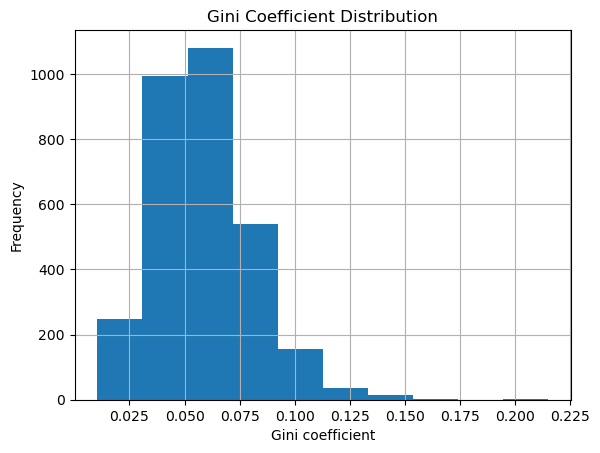

In [270]:
county_gini['gini_temporal'].hist()
plt.title('Gini Coefficient Distribution')
plt.ylabel('Frequency')
plt.xlabel('Gini coefficient')
plt.show()

## Lorenz curve

### [HELPER FUNCTION]: `get_lorenz_coordinates()`

In [271]:
def get_lorenz_coordinates(values):
    '''This function calculates Lorenz curve coordinates.

    Args:
        values: Series of values to create Lorenz curve coordinates.

    Returns: 
        Dataframe with Lorenz curve coordinates.
    '''
    # clean, sort, and reset the values
    x = (
        clean_numeric(values)
        .sort_values()
        .reset_index(drop=True)
    )

    # check if empty 
    if x.empty:
        return pd.DataFrame(
            columns=["cum_county_share", "cum_pir_share"]
        )

    # check for nonnegative values
    if x.lt(0).any():
        raise ValueError(
            "Lorenz curve requires nonnegative values."
        )

    total = x.sum()

    cum_pir_share = (
        x.cumsum() / total
        if total != 0
        else pd.Series(0.0, index=x.index)
    )

    result = pd.DataFrame({
        "cum_county_share":
            pd.Series(range(1, len(x) + 1)) / len(x),

        "cum_pir_share":
            cum_pir_share
    })

    return pd.concat(
        [
            pd.DataFrame({
                "cum_county_share": [0.0],
                "cum_pir_share": [0.0]
            }),
            result
        ],
        ignore_index=True
    )

### [HELPER FUNCTION]: `plot_lorenz_curve()`

In [272]:
def plot_lorenz_curve(selected_year, df):
    '''This function creates a Lorenz curve plot.
    
    Args:
        selected_year: Year for plot.
        df: Dataframe from which to calculate Lorenz curve coordinates.
    '''

    # get PIR for selected year
    pir_selected_year = df.loc[df["Year"] == selected_year, "PIR"]

    # calculate Lorenz coordinates
    lorenz_coordinates = get_lorenz_coordinates(pir_selected_year)

    # create plot
    plt.figure(figsize=(7, 7))

    plt.plot(lorenz_coordinates['cum_county_share'], lorenz_coordinates['cum_pir_share'], label=f"{selected_year} County PIR")
    plt.plot([0, 1], [0,1], linestyle="--", label="Equal distribution")
    
    plt.xlabel("Cumulative share of counties")
    plt.ylabel("Cumulative share of total county PIR")
    plt.title(f"Lorenz Curve of County-level Housing Affordability, {selected_year}")
    plt.legend()
    plt.show()

### Lorenz Curves of County-level Housing Affordability; 2016, 2020, 2024

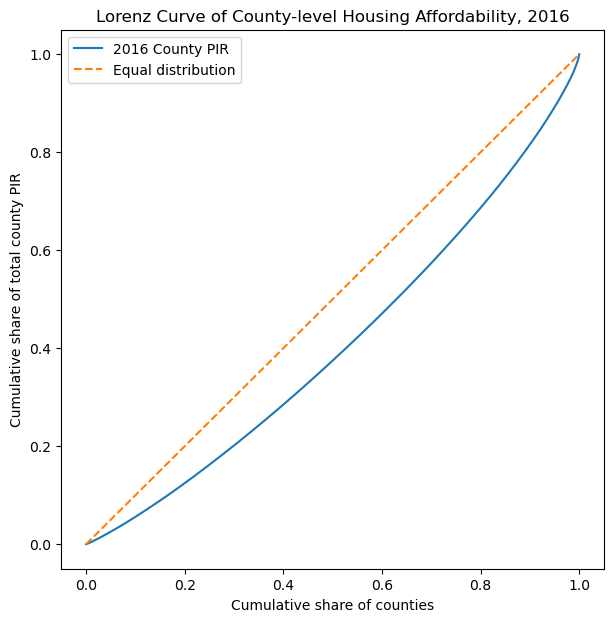

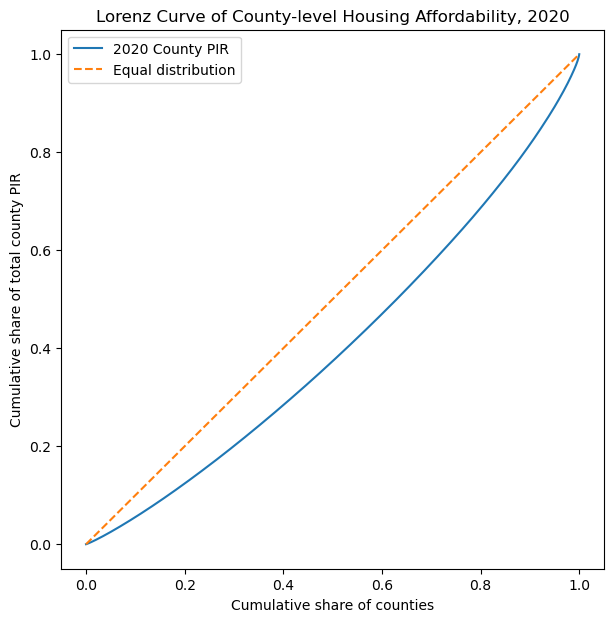

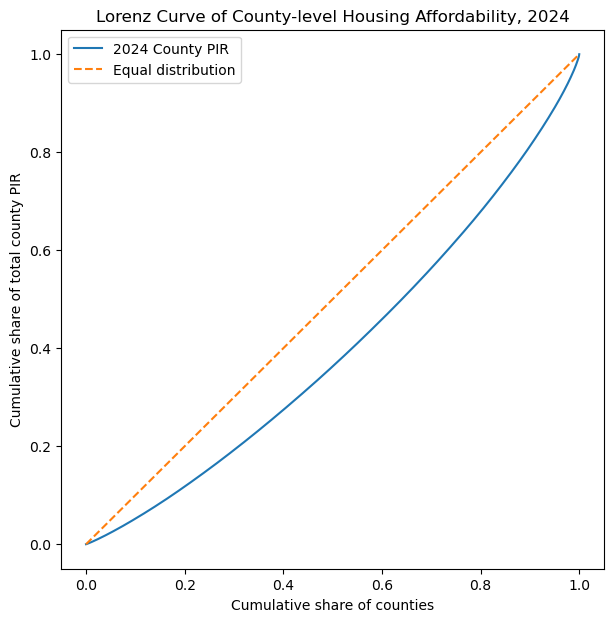

In [273]:
years_to_plot = [2016, 2020, 2024]

for year in years_to_plot:
    plot_lorenz_curve(year, housing_analysis_ext)

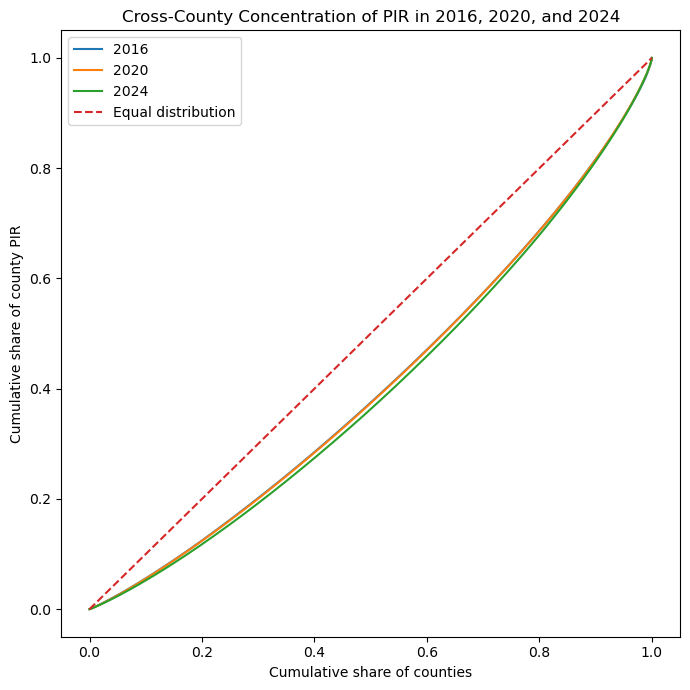

In [274]:
years_to_plot = [2016, 2020, 2024]
plt.figure(figsize=(7, 7))

for year in years_to_plot:
    coordinates = get_lorenz_coordinates(
        housing_analysis_ext.loc[housing_analysis_ext["Year"].eq(year), "PIR"]
    )
    plt.plot(
        coordinates["cum_county_share"],
        coordinates["cum_pir_share"],
        label=str(year)
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Equal distribution")
plt.xlabel("Cumulative share of counties")
plt.ylabel("Cumulative share of county PIR")
plt.title("Cross-County Concentration of PIR in 2016, 2020, and 2024")
plt.legend()
plt.tight_layout()
plt.show()

**Note:** The Lorenz curve describes the relative concentration of county-level PIR values across counties. It does not represent the share of households, housing units, or total housing costs.

## Percentile ratios

### [HELPER FUNCTION]: `calculate_percentile_ratios()`

In [275]:
def calculate_percentile_ratios(values):
    '''This function calculates the percentile ratios.

    Args:
        values: Series like set of values to calculate percentile ratios for. 
    
    Returns: 
        Series with percentiles and ratios: 
            p25: 25th percentile
            p50: 50th percentile
            p75: 75th percentile
            p90: 90th percentile
            p90_p50: Ratio of 90th percentile to 50th percentile
            p90_p10: Ratio of 90th percentile to 10th percentile
            p75_p25: Ratio of 75th percentile to 25th percentile

    '''
    x = clean_numeric(values)

    # empty result for values below sample threshold
    empty_result = {
        "p10": np.nan,
        "p25": np.nan,
        "p50": np.nan,
        "p75": np.nan,
        "p90": np.nan,
        "p90_p50": np.nan,
        "p90_p10": np.nan,
        "p75_p25": np.nan
    }

    # check sample size
    if len(x) < 2:
        return pd.Series( # return empty series for values below threshold
            empty_result,
            dtype=float
        )

    # define percentiles 
    percentiles = x.quantile([0.10, 0.25, 0.50, 0.75, 0.90])

    # locate specific percentiles
    p10 = percentiles.loc[0.10]
    p25 = percentiles.loc[0.25]
    p50 = percentiles.loc[0.50]
    p75 = percentiles.loc[0.75]
    p90 = percentiles.loc[0.90]

    # return series with percentiles and ratios
    return pd.Series({
        "p10": p10,
        "p25": p25,
        "p50": p50,
        "p75": p75,
        "p90": p90,
        "p90_p50": p90 / p50 if p50 != 0 else np.nan,
        "p90_p10": p90 / p10 if p10 != 0 else np.nan,
        "p75_p25": p75 / p25 if p25 != 0 else np.nan
    })

### Annual Percentile Ratios

In [276]:
annual_percentile_ratios = (
    housing_analysis_ext
        .groupby("Year")["PIR"]
        .apply(calculate_percentile_ratios)
        .unstack()
        .reset_index()
)

annual_percentile_ratios

,Year,p10,p25,p50,p75,p90,p90_p50,p90_p10,p75_p25
0,2016,1.997722,2.405588,2.895309,3.516675,4.407616,1.522330,2.206322,1.461878
1,2017,1.989982,2.416328,2.895363,3.518747,4.443424,1.534669,2.232897,1.456237
2,2018,2.008634,2.441643,2.947411,3.582874,4.557066,1.546125,2.268739,1.467403
3,2019,1.998063,2.429508,2.927844,3.562478,4.509253,1.540128,2.256812,1.466337
4,2020,2.083543,2.510717,3.047709,3.680837,4.690787,1.539119,2.251351,1.466050
5,2021,2.303277,2.791069,3.383096,4.134363,5.385393,1.591853,2.338144,1.481283
6,2022,2.363491,2.864805,3.499795,4.402570,5.709356,1.631340,2.415645,1.536779
7,2023,2.307775,2.796682,3.445991,4.288894,5.493528,1.594179,2.380443,1.533565
8,2024,2.194205,2.705700,3.368648,4.194820,5.357369,1.590362,2.441600,1.550364


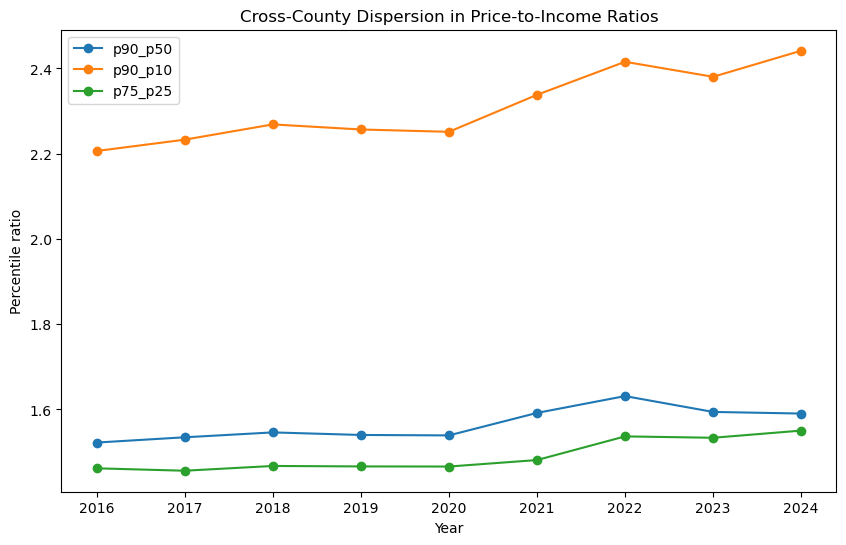

In [277]:
annual_percentile_ratios.plot(
    x="Year",
    y=[
        "p90_p50",
        "p90_p10",
        "p75_p25"
    ],
    marker="o",
    figsize=(10, 6)
)

plt.ylabel("Percentile ratio")
plt.title("Cross-County Dispersion in Price-to-Income Ratios")
plt.show()

### County Percentile Ratios

In [278]:
county_percentile_ratios = (
    housing_analysis_ext
        .groupby("FIPS")['PIR']
        .apply(calculate_percentile_ratios)
        .unstack() # move ratios to columns
        .reset_index()
)

county_percentile_ratios.head()

,FIPS,p10,p25,p50,p75,p90,p90_p50,p90_p10,p75_p25
0,01001,2.900321,2.933292,3.106296,3.147688,3.337358,1.074385,1.150686,1.073091
1,01003,3.692670,3.840312,4.044677,4.677310,4.973691,1.229688,1.346909,1.217951
2,01005,3.247621,3.321364,3.347427,3.493717,3.746421,1.119194,1.153590,1.051892
3,01007,3.305808,3.354131,3.440362,3.965721,4.041624,1.174767,1.222583,1.182339
4,01009,3.127189,3.171751,3.258903,3.503726,3.581317,1.098933,1.145219,1.104666


In [279]:
county_percentile_ratios.info()

<class 'pandas.DataFrame'>
RangeIndex: 3072 entries, 0 to 3071
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   FIPS     3072 non-null   str    
 1   p10      3070 non-null   float64
 2   p25      3070 non-null   float64
 3   p50      3070 non-null   float64
 4   p75      3070 non-null   float64
 5   p90      3070 non-null   float64
 6   p90_p50  3070 non-null   float64
 7   p90_p10  3070 non-null   float64
 8   p75_p25  3070 non-null   float64
dtypes: float64(8), str(1)
memory usage: 231.5 KB


## Coefficient of variation

### [HELPER FUNCTION]: `coefficient_of_variation()`

In [280]:
def coefficient_of_variation(values):
    '''This function calculates the coefficient of variation.

    Args:
        values: Series of values to perform calculation on.
    
    Returns:
        Series of values containing coefficent of variation based on input values.
    '''

    # clean input values
    x = clean_numeric(values)

    # check sample size and mean (if mean = 0, division by 0 in CV)
    if len(x) < 2 or x.mean() == 0:
        return np.nan # return NaN 

    # return coefficient of variation
    return float(x.std() / x.mean())

### Annual Coefficient of Variation

In [281]:
annual_cv = (
    housing_analysis_ext
        .groupby("Year")["PIR"]
        .agg(
            county_count="count",
            mean_pir="mean",
            median_pir="median",
            std_pir="std",
            cv_spatial=coefficient_of_variation
        )
        .reset_index()
)

annual_cv

,Year,county_count,mean_pir,median_pir,std_pir,cv_spatial
0,2016,2972,3.122430,2.895309,1.231204,0.394310
1,2017,2979,3.126635,2.895363,1.232954,0.394339
2,2018,2987,3.182767,2.947411,1.263116,0.396861
3,2019,3005,3.161346,2.927844,1.241022,0.392561
4,2020,3009,3.277196,3.047709,1.267821,0.386861
5,2021,3021,3.674664,3.383096,1.475773,0.401608
6,2022,3052,3.850945,3.499795,1.605074,0.416800
7,2023,3061,3.752564,3.445991,1.530543,0.407866
8,2024,3063,3.643698,3.368648,1.488243,0.408443


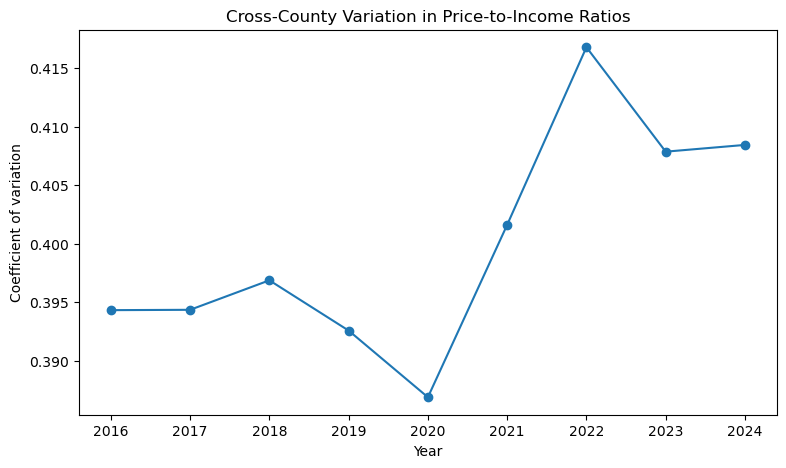

In [282]:
annual_cv.plot(
    x="Year",
    y="cv_spatial",
    marker="o",
    figsize=(9, 5),
    legend=False
)

plt.ylabel("Coefficient of variation")
plt.title("Cross-County Variation in Price-to-Income Ratios")
plt.show()

### Annual dispersion: percentile ratios and coefficient of variation

In [283]:
annual_dispersion = annual_cv.merge(
    annual_percentile_ratios,
    on="Year",
    how="left"
)

annual_dispersion

,Year,county_count,mean_pir,median_pir,std_pir,cv_spatial,p10,p25,p50,p75,p90,p90_p50,p90_p10,p75_p25
0,2016,2972,3.122430,2.895309,1.231204,0.394310,1.997722,2.405588,2.895309,3.516675,4.407616,1.522330,2.206322,1.461878
1,2017,2979,3.126635,2.895363,1.232954,0.394339,1.989982,2.416328,2.895363,3.518747,4.443424,1.534669,2.232897,1.456237
2,2018,2987,3.182767,2.947411,1.263116,0.396861,2.008634,2.441643,2.947411,3.582874,4.557066,1.546125,2.268739,1.467403
3,2019,3005,3.161346,2.927844,1.241022,0.392561,1.998063,2.429508,2.927844,3.562478,4.509253,1.540128,2.256812,1.466337
4,2020,3009,3.277196,3.047709,1.267821,0.386861,2.083543,2.510717,3.047709,3.680837,4.690787,1.539119,2.251351,1.466050
5,2021,3021,3.674664,3.383096,1.475773,0.401608,2.303277,2.791069,3.383096,4.134363,5.385393,1.591853,2.338144,1.481283
6,2022,3052,3.850945,3.499795,1.605074,0.416800,2.363491,2.864805,3.499795,4.402570,5.709356,1.631340,2.415645,1.536779
7,2023,3061,3.752564,3.445991,1.530543,0.407866,2.307775,2.796682,3.445991,4.288894,5.493528,1.594179,2.380443,1.533565
8,2024,3063,3.643698,3.368648,1.488243,0.408443,2.194205,2.705700,3.368648,4.194820,5.357369,1.590362,2.441600,1.550364


### County coefficient of variation

In [284]:
county_cv = (
    housing_analysis_ext
        .groupby('FIPS')['PIR']
        .agg(
            n_years="count",
            mean_pir="mean",
            std_pir="std",
            min_pir="min",
            max_pir="max",
            cv_temporal=coefficient_of_variation
        )
        .reset_index()
)

county_cv.head()

,FIPS,n_years,mean_pir,std_pir,min_pir,max_pir,cv_temporal
0,01001,9,3.104125,0.202370,2.833130,3.489840,0.065194
1,01003,9,4.270883,0.532123,3.675297,4.999481,0.124593
2,01005,9,3.425160,0.220310,3.145505,3.826739,0.064321
3,01007,9,3.609690,0.328132,3.270382,4.083644,0.090903
4,01009,9,3.324976,0.222621,3.101743,3.750137,0.066954


In [285]:
county_cv.info()

<class 'pandas.DataFrame'>
RangeIndex: 3072 entries, 0 to 3071
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   FIPS         3072 non-null   str    
 1   n_years      3072 non-null   int64  
 2   mean_pir     3072 non-null   float64
 3   std_pir      3070 non-null   float64
 4   min_pir      3072 non-null   float64
 5   max_pir      3072 non-null   float64
 6   cv_temporal  3070 non-null   float64
dtypes: float64(5), int64(1), str(1)
memory usage: 183.5 KB


In [286]:
# merge county names 
county_cv = county_cv.merge(
    county_lookup,
    on="FIPS",
    how="left"
)

# sort values 
county_cv = (
    county_cv
        .sort_values(
            "cv_temporal",
            ascending=False
        )
        .reset_index(drop=True)
)

county_cv.head()

,FIPS,n_years,mean_pir,std_pir,min_pir,max_pir,cv_temporal,CountyName,StateAbbr
0,51730,9,2.764151,1.149794,1.575238,4.442840,0.415966,Petersburg City,VA
1,08079,9,5.495145,2.212824,3.979186,11.070889,0.402687,Mineral County,CO
2,22027,9,6.835737,2.170562,2.975298,9.118097,0.317532,Claiborne Parish,LA
3,17171,9,2.377484,0.714925,1.467963,3.698842,0.300706,Scott County,IL
4,30075,9,2.915873,0.852220,2.052243,4.104928,0.292269,Powder River County,MT


# Metric Validation: Comparison of Housing Affordability Metrics
This section compares the affordabilty metrics as determined by various distributions from above (i.e., pareto_composite, gini_temporal, cv_temporal, percentile ratios). 

| Metric               | What it summarizes                                          | Interpretation                                                  |
| -------------------- | ----------------------------------------------------------- | --------------------------------------------------------------- |
| Median PIR       | Center of the 9-year PIR distribution                       | Typical affordability burden                                |
| Pareto composite | Distributional characteristics, including the upper tail    | Affordability burden + extreme affordability conditions     |
| Gini             | Inequality/dispersion among the 9 PIR observations          | How uneven affordability has been across years              |
| CV               | Standard deviation relative to mean PIR                     | Relative year-to-year variability                           |
| Percentile ratio | Distance between higher and lower parts of the distribution | Spread between relatively affordable and unaffordable years |


## County summary

In [287]:
county_summary = (
    housing_analysis_ext
    .groupby("FIPS")
    .agg(
        # Count how many annual observations are available.
        n_years=("Year", "nunique"),

        # Mean PIR across the analysis period.
        mean_pir=("PIR", "mean"),

        # Median PIR represents persistent affordability level.
        median_pir=("PIR", "median"),

        # Latest PIR represents current affordability level.
        latest_pir=("PIR", "last"),

        # Temporal Gini measures unevenness across annual PIR values.
        gini_temporal=("PIR", calc_gini_coefficient),

        # Temporal CV measures relative annual PIR variability.
        cv_temporal=("PIR", coefficient_of_variation)
    )
    .reset_index()
)

In [288]:
county_summary.head()

,FIPS,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal
0,01001,9,3.104125,3.106296,3.147688,0.033827,0.065194
1,01003,9,4.270883,4.044677,4.554366,0.065639,0.124593
2,01005,9,3.425160,3.347427,3.347427,0.032249,0.064321
3,01007,9,3.609690,3.440362,3.607797,0.046610,0.090903
4,01009,9,3.324976,3.258903,3.290588,0.034082,0.066954


## Percentile results

In [289]:
# retain the percentiles needed for interpretation and the primary P90/P10 comparison metric.
percentile_results = county_percentile_ratios[["FIPS", "p10", "p50", "p90", "p90_p10"]]

percentile_results.head()

,FIPS,p10,p50,p90,p90_p10
0,01001,2.900321,3.106296,3.337358,1.150686
1,01003,3.692670,4.044677,4.973691,1.346909
2,01005,3.247621,3.347427,3.746421,1.153590
3,01007,3.305808,3.440362,4.041624,1.222583
4,01009,3.127189,3.258903,3.581317,1.145219


## Metric comparison
The following creates a unified table with the metrics and the original county information for comparison. 

In [290]:
metric_comparison = (
    county_lookup
    .merge(
        county_summary[['FIPS', 'n_years', 'mean_pir', 'median_pir', 'latest_pir',
       'gini_temporal', 'cv_temporal']],
        on="FIPS",
        how="left",
        validate="one_to_one"
    )
    .merge(
        percentile_results[['FIPS', 'p10', 'p50', 'p90', 'p90_p10']],
        on="FIPS",
        how="left",
        validate="one_to_one"
    )
    .merge(
        pareto_dist[['FIPS', 'alpha', 'xmin', 'ks_distance', 'n_obs', 'n_tail', 'tail_share', 'alpha_norm', 'xmin_norm', 'pareto_composite']],
        on="FIPS",
        how="left",
        validate="one_to_one"
    )
)

metric_comparison.head()

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,alpha_norm,xmin_norm,pareto_composite
0,01001,Autauga County,AL,9,3.104125,3.106296,3.147688,0.033827,0.065194,2.900321,...,1.150686,25.962860,3.079919,0.153755,9.0,6.0,0.666667,0.031674,0.124458,0.078066
1,01003,Baldwin County,AL,9,4.270883,4.044677,4.554366,0.065639,0.124593,3.692670,...,1.346909,7.975322,3.675297,0.220392,9.0,9.0,1.000000,0.006804,0.158882,0.082843
2,01005,Barbour County,AL,9,3.425160,3.347427,3.347427,0.032249,0.064321,3.247621,...,1.153590,19.507765,3.273150,0.159280,9.0,8.0,0.888889,0.022749,0.135631,0.079190
3,01007,Bibb County,AL,9,3.609690,3.440362,3.607797,0.046610,0.090903,3.305808,...,1.222583,11.512153,3.270382,0.201543,9.0,9.0,1.000000,0.011694,0.135470,0.073582
4,01009,Blount County,AL,9,3.324976,3.258903,3.290588,0.034082,0.066954,3.127189,...,1.145219,15.800596,3.101743,0.168635,9.0,9.0,1.000000,0.017623,0.125720,0.071672


In [291]:
metric_comparison['pareto_usable'] = metric_comparison['n_tail'] >= 3
metric_comparison.head()

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,alpha_norm,xmin_norm,pareto_composite,pareto_usable
0,01001,Autauga County,AL,9,3.104125,3.106296,3.147688,0.033827,0.065194,2.900321,...,25.962860,3.079919,0.153755,9.0,6.0,0.666667,0.031674,0.124458,0.078066,True
1,01003,Baldwin County,AL,9,4.270883,4.044677,4.554366,0.065639,0.124593,3.692670,...,7.975322,3.675297,0.220392,9.0,9.0,1.000000,0.006804,0.158882,0.082843,True
2,01005,Barbour County,AL,9,3.425160,3.347427,3.347427,0.032249,0.064321,3.247621,...,19.507765,3.273150,0.159280,9.0,8.0,0.888889,0.022749,0.135631,0.079190,True
3,01007,Bibb County,AL,9,3.609690,3.440362,3.607797,0.046610,0.090903,3.305808,...,11.512153,3.270382,0.201543,9.0,9.0,1.000000,0.011694,0.135470,0.073582,True
4,01009,Blount County,AL,9,3.324976,3.258903,3.290588,0.034082,0.066954,3.127189,...,15.800596,3.101743,0.168635,9.0,9.0,1.000000,0.017623,0.125720,0.071672,True


In [292]:
metric_comparison['pareto_usable'].value_counts()

pareto_usable
True     3009
False      63
Name: count, dtype: int64

## Comparison sample
The following creates a comparison sample to be used in comparing the metrics mean_pir, median_pir, pareto_composite, gini_temporal, cv_temporal, and p90_p10. 

In [293]:
# create one common comparison sample
validation_metrics = ["mean_pir", "median_pir", "pareto_composite", "gini_temporal", "cv_temporal", "p90_p10"]

# keep counties with every primary validation metric available.
comparison_sample = (
    metric_comparison
    .dropna(subset=validation_metrics)
    .copy()
)

# if a Pareto usability flag exists, retain only usable fits.
if "pareto_usable" in comparison_sample.columns:
    comparison_sample = comparison_sample.loc[comparison_sample["pareto_usable"]].copy()

print("Counties in final comparison sample:", len(comparison_sample))

Counties in final comparison sample: 3009


In [294]:
comparison_sample.head()

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,alpha,xmin,ks_distance,n_obs,n_tail,tail_share,alpha_norm,xmin_norm,pareto_composite,pareto_usable
0,01001,Autauga County,AL,9,3.104125,3.106296,3.147688,0.033827,0.065194,2.900321,...,25.962860,3.079919,0.153755,9.0,6.0,0.666667,0.031674,0.124458,0.078066,True
1,01003,Baldwin County,AL,9,4.270883,4.044677,4.554366,0.065639,0.124593,3.692670,...,7.975322,3.675297,0.220392,9.0,9.0,1.000000,0.006804,0.158882,0.082843,True
2,01005,Barbour County,AL,9,3.425160,3.347427,3.347427,0.032249,0.064321,3.247621,...,19.507765,3.273150,0.159280,9.0,8.0,0.888889,0.022749,0.135631,0.079190,True
3,01007,Bibb County,AL,9,3.609690,3.440362,3.607797,0.046610,0.090903,3.305808,...,11.512153,3.270382,0.201543,9.0,9.0,1.000000,0.011694,0.135470,0.073582,True
4,01009,Blount County,AL,9,3.324976,3.258903,3.290588,0.034082,0.066954,3.127189,...,15.800596,3.101743,0.168635,9.0,9.0,1.000000,0.017623,0.125720,0.071672,True


In [295]:
comparison_sample.info()

<class 'pandas.DataFrame'>
Index: 3009 entries, 0 to 3071
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   FIPS              3009 non-null   str    
 1   CountyName        3009 non-null   str    
 2   StateAbbr         3009 non-null   str    
 3   n_years           3009 non-null   int64  
 4   mean_pir          3009 non-null   float64
 5   median_pir        3009 non-null   float64
 6   latest_pir        3009 non-null   float64
 7   gini_temporal     3009 non-null   float64
 8   cv_temporal       3009 non-null   float64
 9   p10               3009 non-null   float64
 10  p50               3009 non-null   float64
 11  p90               3009 non-null   float64
 12  p90_p10           3009 non-null   float64
 13  alpha             3009 non-null   float64
 14  xmin              3009 non-null   float64
 15  ks_distance       3009 non-null   float64
 16  n_obs             3009 non-null   float64
 17  n_tail     

## Coverage table
The following displays a table of the amount of coverage the metric covers for U.S. counties. The original usable data contained 3072 counties.

In [296]:
coverage_table = pd.DataFrame(
    {
        "valid_count": (
            metric_comparison[validation_metrics].notna().sum() # calculate sum of non-NaN values
        ),
        "coverage_pct": (
            metric_comparison[validation_metrics].notna().mean().mul(100) # calculate percentage of coverage using mean and non-NaN values
        )
    }
)

coverage_table = coverage_table.sort_values("coverage_pct", ascending=False)

coverage_table

,valid_count,coverage_pct
mean_pir,3072,100.000000
median_pir,3072,100.000000
gini_temporal,3070,99.934896
cv_temporal,3070,99.934896
p90_p10,3070,99.934896
pareto_composite,3009,97.949219


The `pareto_composite` covers the lowest pecentage (97.9%) of the data values represented, however this is still a significnat portion of the data. The excluded values are most likely attributed to (a) not having enough data points to create a Pareto distribution or (b) beneath the threshold of the useable fits. 

## Descriptive statistics

In [297]:
# descriptive statistics
descriptive_statistics = comparison_sample[validation_metrics].describe().T

# add skewness to identify asymmetric distributions
descriptive_statistics["skewness"] = comparison_sample[validation_metrics].skew()

descriptive_statistics

,count,mean,std,min,25%,50%,75%,max,skewness
mean_pir,3009.0,3.425252,1.340174,1.159642,2.614764,3.162166,3.850230,21.446528,3.035875
median_pir,3009.0,3.334143,1.289936,1.054085,2.557157,3.094079,3.739496,20.285054,3.004235
pareto_composite,3009.0,0.078511,0.045498,0.001917,0.050924,0.068511,0.093688,0.594307,3.052336
gini_temporal,3009.0,0.058474,0.021533,0.014595,0.042745,0.056732,0.070938,0.214955,0.855050
cv_temporal,3009.0,0.112368,0.041428,0.027809,0.082342,0.108698,0.136443,0.415966,0.924060
p90_p10,3009.0,1.283486,0.124777,1.058229,1.195148,1.266651,1.347063,2.601118,1.519123


- Skewness
    - mean_pir, median_pir, and pareto_composite all exhibit similar skewness values of approximately 3.0. This indicates a heavy right skewness in the distribution.
        - **This indicates that these distributions are more skewed and might not provide a comparative measure.** 
    - gini_temporal (0.86) and cv_temporal (0.92) exhibit similar values of skewness; with the gini_temporal being slightly more symmetric. 
        - **This indicates that the gini_temporal and cv_temporal metrics are more symmetric, less skewed when describing the housing values. Thus, might provide a better measure for comparing measurements of housing affordability.**
    - p90_p10 is in the middle with a skewness of 1.5
    - These findings are further justified in the histograms below

## Histograms

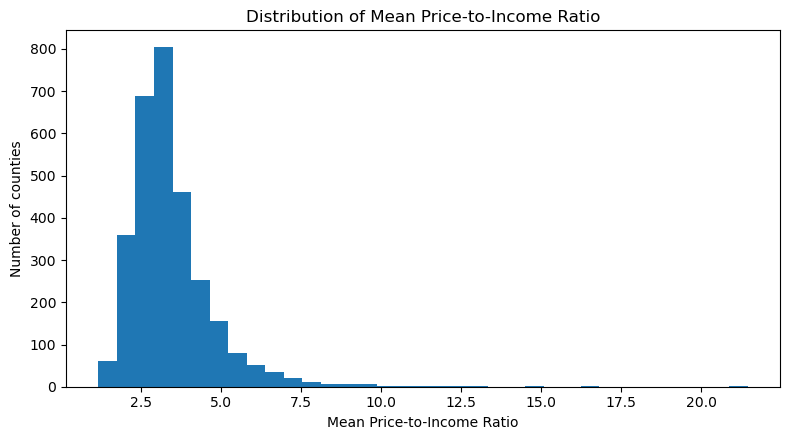

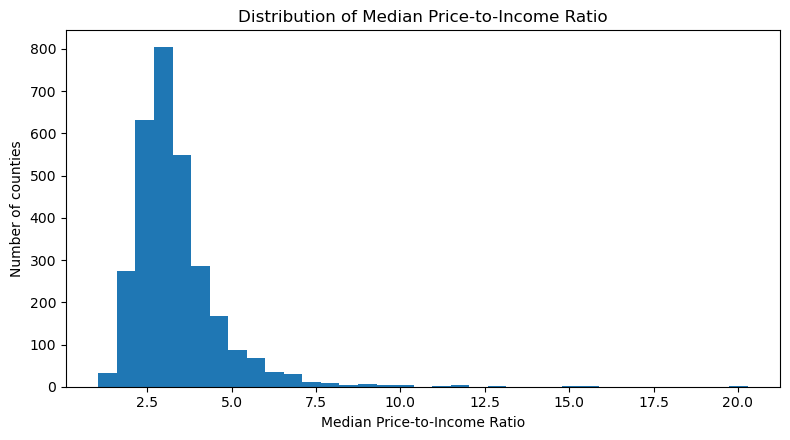

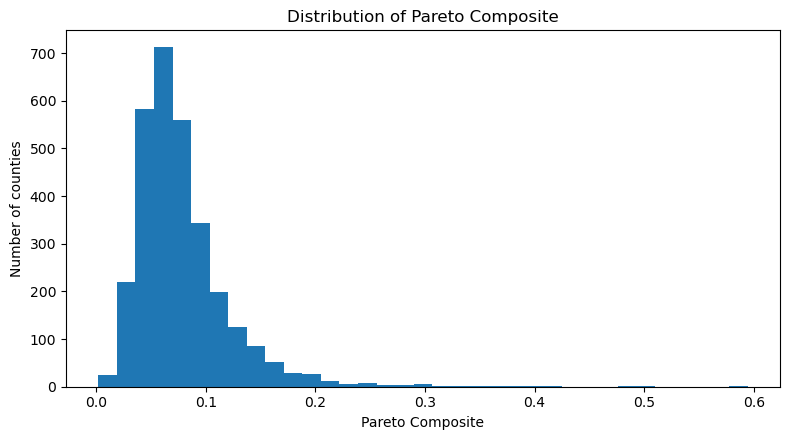

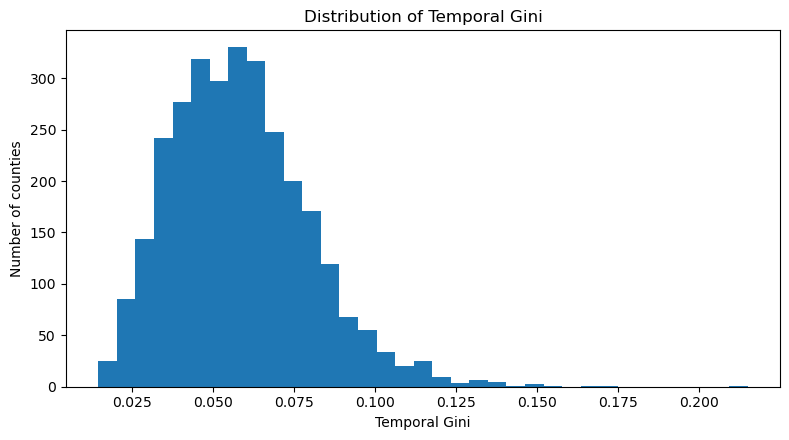

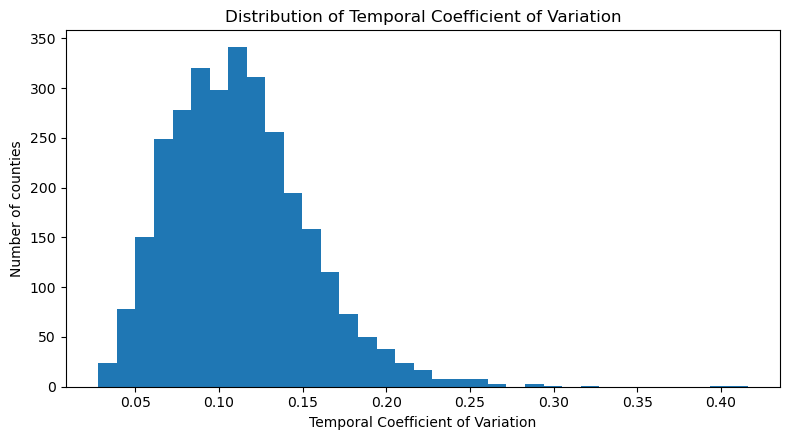

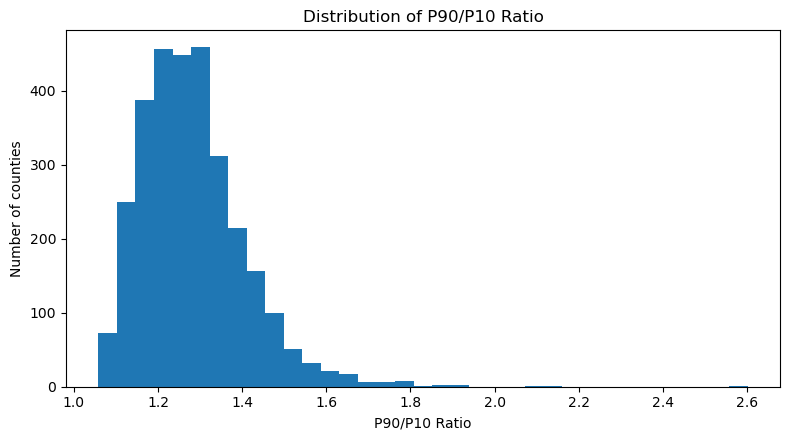

In [298]:
metric_labels = {
    "mean_pir": "Mean Price-to-Income Ratio",
    "median_pir": "Median Price-to-Income Ratio",
    "pareto_composite": "Pareto Composite",
    "gini_temporal": "Temporal Gini",
    "cv_temporal": "Temporal Coefficient of Variation",
    "p90_p10": "P90/P10 Ratio"
}

# create one chart per metric rather than a crowded subplot
for metric in validation_metrics:
    plt.figure(figsize=(8, 4.5))

    comparison_sample[metric].plot.hist(bins=35)

    plt.xlabel(metric_labels[metric])
    plt.ylabel("Number of counties")
    plt.title(f"Distribution of {metric_labels[metric]}")

    plt.tight_layout()
    plt.show()

## Pareto fit summary

In [299]:
pareto_fit_summary = pd.Series(
    {
        "counties_with_valid_pareto": comparison_sample["pareto_composite"].notna().sum(),

        "median_total_observations":
            comparison_sample[
                "pareto_n_obs"
            ].median()
            if "pareto_n_obs"
            in comparison_sample.columns
            else comparison_sample[
                "n_years"
            ].median(),

        "median_tail_observations":
            comparison_sample[
                "n_tail"
            ].median()
            if "n_tail"
            in comparison_sample.columns
            else np.nan,

        "median_ks_distance":
            comparison_sample[
                "ks_distance"
            ].median()
            if "ks_distance"
            in comparison_sample.columns
            else np.nan
    }
)


pareto_fit_summary

counties_with_valid_pareto    3009.000000
median_total_observations        9.000000
median_tail_observations         8.000000
median_ks_distance               0.201848
dtype: float64

In [300]:
ks_summary = (
    comparison_sample["ks_distance"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
)

ks_summary

count    3009.000000
mean        0.202746
std         0.035188
min         0.079250
10%         0.157652
25%         0.180121
50%         0.201848
75%         0.226484
90%         0.247598
95%         0.260539
max         0.346506
Name: ks_distance, dtype: float64

In [301]:
comparison_sample["ks_distance"].describe(
    percentiles=[
        .10,
        .25,
        .50,
        .75,
        .90,
        .95
    ]
)

count    3009.000000
mean        0.202746
std         0.035188
min         0.079250
10%         0.157652
25%         0.180121
50%         0.201848
75%         0.226484
90%         0.247598
95%         0.260539
max         0.346506
Name: ks_distance, dtype: float64

The median KS distance was 0.202, with 50% of county fits falling between approximately 0.18 and 0.23.

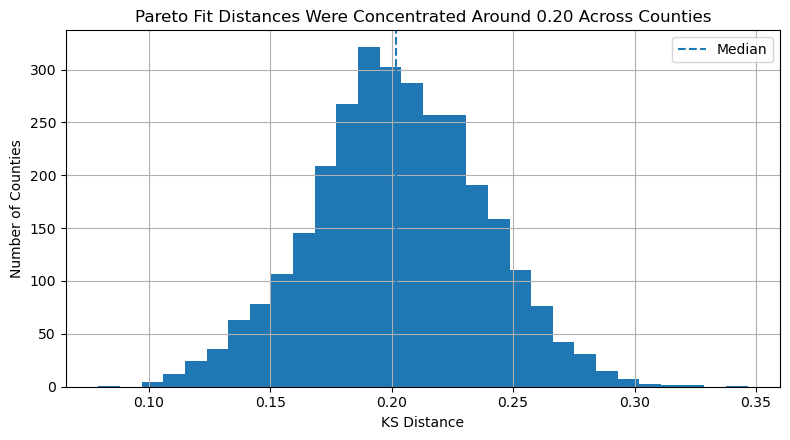

In [302]:
plt.figure(figsize=(8, 4.5))

comparison_sample["ks_distance"].hist(bins=30)

plt.axvline(comparison_sample["ks_distance"].median(),linestyle="--",label="Median")

plt.xlabel("KS Distance")
plt.ylabel("Number of Counties")

plt.title("Pareto Fit Distances Were Concentrated Around 0.20 Across Counties")

plt.legend()
plt.tight_layout()
plt.show()

### Interpretation: Pareto Fit Assessment
Pareto parameters were successfully estimated for 3,009 counties. The median county contained nine annual PIR observations, with eight observations included in the fitted Pareto tail. The median Kolmogorov–Smirnov (KS) distance was 0.202. KS distances were approximately symmetric and concentrated around 0.20, indicating that the median was representative of the typical discrepancy between observed county PIR distributions and their fitted Pareto distributions. Because the Pareto fitting procedure uses the KS distance when selecting the lower-tail threshold (xmin), and because county time series contain relatively few observations, the KS statistic is interpreted as a comparative fit diagnostic rather than proof that county PIR values follow a Pareto distribution.

## Correlation
This section examines the correlation between mean_pir, median_pir, pareto_composite, gini_temporal, cv_temporal, and p90_p10. 

### Spearman rank correlation
The Spearman correlation method was selected because not all distribution values are normalized (e.g., mean_pir, median_pir). 

In [303]:
spearman_correlation = comparison_sample[validation_metrics].corr(method="spearman")

spearman_correlation

,mean_pir,median_pir,pareto_composite,gini_temporal,cv_temporal,p90_p10
mean_pir,1.000000,0.991397,0.758768,0.164577,0.163131,0.163743
median_pir,0.991397,1.000000,0.782020,0.112035,0.108831,0.114122
pareto_composite,0.758768,0.782020,1.000000,-0.103348,-0.099552,-0.115724
gini_temporal,0.164577,0.112035,-0.103348,1.000000,0.997101,0.982451
cv_temporal,0.163131,0.108831,-0.099552,0.997101,1.000000,0.976315
p90_p10,0.163743,0.114122,-0.115724,0.982451,0.976315,1.000000


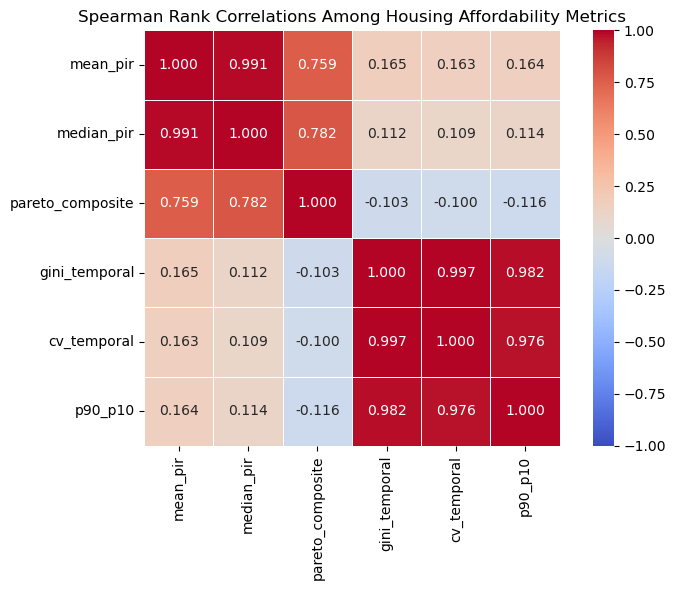

In [304]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    spearman_correlation,
    annot=True,
    fmt=".3f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Spearman Rank Correlations Among Housing Affordability Metrics")

plt.tight_layout()
plt.show()

- pareto_composite has a weak, negative correlated to gini_temporal (-0.10), cv_temporal (-0.10), and p90_p10 (-0.12)
    - This doesn't mean it's not a good measurement. It could be measuring something the other distributions do not. 
- pareto_composite has a similar corrleations with the mean_pir (0.76) and median_pir (0.78); both positive and strong
    - This indicates that the pareto_composite measures something similar to the mean and median. 
- gini_temporal, cv_temporal, and p90_p10 have a strong, positive correlation with each other of or near 1.0
    - gini_temporal and cv_temporal have a correlation of 1.00
    - This is a strong indicator they are measuring the same thing

### Heatmap half

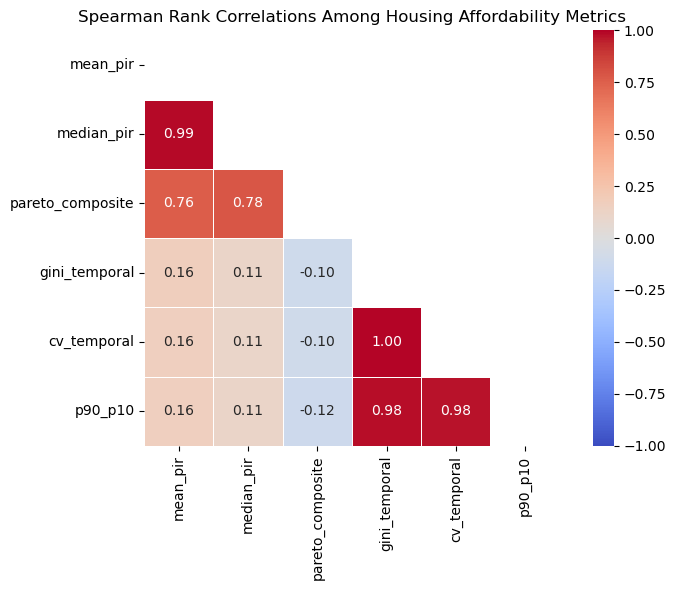

In [305]:
# create a mask for the upper triangle
mask = np.triu(np.ones_like(spearman_correlation, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    spearman_correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Spearman Rank Correlations Among Housing Affordability Metrics")

plt.tight_layout()
plt.show()

### Absolute correlation: strongest relationship

In [306]:
# copy the absolute correlation matrix.
absolute_correlation = spearman_correlation.abs().copy()

# convert the DataFrame to a separate writable NumPy array.
correlation_array = absolute_correlation.to_numpy(copy=True)

# replace the self-correlations on the diagonal with NaN.
np.fill_diagonal(correlation_array, np.nan)

# convert the modified array back into a DataFrame,
# preserving the original row and column labels.
absolute_correlation = pd.DataFrame(
    correlation_array,
    index=absolute_correlation.index,
    columns=absolute_correlation.columns
)

# identify the strongest relationship for each metric.
strongest_relationship = pd.DataFrame(
    {
        "strongest_other_correlation":absolute_correlation.max(axis=1),
        "most_similar_metric":absolute_correlation.idxmax(axis=1)
    }
)

strongest_relationship

,strongest_other_correlation,most_similar_metric
mean_pir,0.991397,median_pir
median_pir,0.991397,mean_pir
pareto_composite,0.782020,median_pir
gini_temporal,0.997101,cv_temporal
cv_temporal,0.997101,gini_temporal
p90_p10,0.982451,gini_temporal


## County ranks

In [307]:
ranked_counties = comparison_sample.copy()

for metric in validation_metrics:

    # rank 1 represents the county with the highest metric value and therefore the greatest relative policy priority
    ranked_counties[f"{metric}_rank"] = (
        ranked_counties[metric]
        .rank(ascending=False, method="min")
    )

    # percentile rank allows comparison when the sample size changes; smaller percentiles represent greater priority
    ranked_counties[f"{metric}_rank_pct"] = (
        ranked_counties[metric]
        .rank(ascending=False, method="average", pct=True)
    )

In [308]:
ranked_counties.head()

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,median_pir_rank,median_pir_rank_pct,pareto_composite_rank,pareto_composite_rank_pct,gini_temporal_rank,gini_temporal_rank_pct,cv_temporal_rank,cv_temporal_rank_pct,p90_p10_rank,p90_p10_rank_pct
0,01001,Autauga County,AL,9,3.104125,3.106296,3.147688,0.033827,0.065194,2.900321,...,1485.0,0.493519,1177.0,0.391160,2680.0,0.890661,2669.0,0.887006,2658.0,0.883350
1,01003,Baldwin County,AL,9,4.270883,4.044677,4.554366,0.065639,0.124593,3.692670,...,576.0,0.191426,1019.0,0.338651,990.0,0.329013,1033.0,0.343303,754.0,0.250582
2,01005,Barbour County,AL,9,3.425160,3.347427,3.347427,0.032249,0.064321,3.247621,...,1144.0,0.380193,1137.0,0.377866,2741.0,0.910934,2694.0,0.895314,2633.0,0.875042
3,01007,Bibb County,AL,9,3.609690,3.440362,3.607797,0.046610,0.090903,3.305808,...,1031.0,0.342639,1318.0,0.438019,2041.0,0.678298,2011.0,0.668328,1977.0,0.657029
4,01009,Blount County,AL,9,3.324976,3.258903,3.290588,0.034082,0.066954,3.127189,...,1262.0,0.419408,1390.0,0.461947,2668.0,0.886673,2632.0,0.874709,2697.0,0.896311


In [309]:
ranked_counties.columns

Index(['FIPS', 'CountyName', 'StateAbbr', 'n_years', 'mean_pir', 'median_pir',
       'latest_pir', 'gini_temporal', 'cv_temporal', 'p10', 'p50', 'p90',
       'p90_p10', 'alpha', 'xmin', 'ks_distance', 'n_obs', 'n_tail',
       'tail_share', 'alpha_norm', 'xmin_norm', 'pareto_composite',
       'pareto_usable', 'mean_pir_rank', 'mean_pir_rank_pct',
       'median_pir_rank', 'median_pir_rank_pct', 'pareto_composite_rank',
       'pareto_composite_rank_pct', 'gini_temporal_rank',
       'gini_temporal_rank_pct', 'cv_temporal_rank', 'cv_temporal_rank_pct',
       'p90_p10_rank', 'p90_p10_rank_pct'],
      dtype='str')

## Top 20 Counties (mean PIR)

In [310]:
# Top 20 counties under mean PIR.
top_mean_pir = (
    ranked_counties
    .sort_values("mean_pir_rank")[["CountyName", "StateAbbr", "mean_pir", "mean_pir_rank"]]
    .head(20)
)

top_mean_pir

,CountyName,StateAbbr,mean_pir,mean_pir_rank
1206,Nantucket County,MA,21.446528,1.0
275,Pitkin County,CO,16.715770,2.0
1826,New York County,NY,14.905355,3.0
3068,Teton County,WY,13.092836,4.0
1200,Dukes County,MA,12.901039,5.0
283,San Miguel County,CO,12.423144,6.0
1819,Kings County,NY,11.834112,7.0
1798,Bronx County,NY,11.752029,8.0
207,San Francisco County,CA,11.013288,9.0
210,San Mateo County,CA,10.502267,10.0


## Top 20 Counties (median PIR)

In [311]:
# Top 20 counties under median PIR.
top_median_pir = (
    ranked_counties
    .sort_values("median_pir_rank")[["CountyName", "StateAbbr", "median_pir", "median_pir_rank"]].head(20)
)

top_median_pir

,CountyName,StateAbbr,median_pir,median_pir_rank
1206,Nantucket County,MA,20.285054,1.0
275,Pitkin County,CO,15.621689,2.0
1826,New York County,NY,14.999891,3.0
3068,Teton County,WY,12.887359,4.0
1819,Kings County,NY,11.961997,5.0
1798,Bronx County,NY,11.917676,6.0
1200,Dukes County,MA,11.860919,7.0
283,San Miguel County,CO,11.422582,8.0
207,San Francisco County,CA,11.058157,9.0
210,San Mateo County,CA,10.363694,10.0


In [312]:
top_median_pir.head(10)

,CountyName,StateAbbr,median_pir,median_pir_rank
1206,Nantucket County,MA,20.285054,1.0
275,Pitkin County,CO,15.621689,2.0
1826,New York County,NY,14.999891,3.0
3068,Teton County,WY,12.887359,4.0
1819,Kings County,NY,11.961997,5.0
1798,Bronx County,NY,11.917676,6.0
1200,Dukes County,MA,11.860919,7.0
283,San Miguel County,CO,11.422582,8.0
207,San Francisco County,CA,11.058157,9.0
210,San Mateo County,CA,10.363694,10.0


## Rank differences relative to median PIR
NOTE: The median was selected over the mean since it is less affected by outliers. 

In [313]:
comparison_metrics = ["pareto_composite", "gini_temporal", "cv_temporal", "p90_p10"]

for metric in comparison_metrics:
    # candidate rank minus median-PIR rank.
    #
    # negative:
    # the alternative metric gives the county greater priority.
    #
    # positive:
    # median PIR gives the county greater priority.
    ranked_counties[f"{metric}_minus_pir_rank"] = ranked_counties[f"{metric}_rank"] - ranked_counties["median_pir_rank"]

    # Absolute difference measures disagreement regardless of direction.
    ranked_counties[f"{metric}_pir_abs_rank_diff"] = ranked_counties[f"{metric}_minus_pir_rank"].abs()

In [314]:
ranked_counties.head()

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff
0,01001,Autauga County,AL,9,3.104125,3.106296,3.147688,0.033827,0.065194,2.900321,...,2658.0,0.883350,-308.0,308.0,1195.0,1195.0,1184.0,1184.0,1173.0,1173.0
1,01003,Baldwin County,AL,9,4.270883,4.044677,4.554366,0.065639,0.124593,3.692670,...,754.0,0.250582,443.0,443.0,414.0,414.0,457.0,457.0,178.0,178.0
2,01005,Barbour County,AL,9,3.425160,3.347427,3.347427,0.032249,0.064321,3.247621,...,2633.0,0.875042,-7.0,7.0,1597.0,1597.0,1550.0,1550.0,1489.0,1489.0
3,01007,Bibb County,AL,9,3.609690,3.440362,3.607797,0.046610,0.090903,3.305808,...,1977.0,0.657029,287.0,287.0,1010.0,1010.0,980.0,980.0,946.0,946.0
4,01009,Blount County,AL,9,3.324976,3.258903,3.290588,0.034082,0.066954,3.127189,...,2697.0,0.896311,128.0,128.0,1406.0,1406.0,1370.0,1370.0,1435.0,1435.0


### Ranked differences summary

In [315]:
rank_difference_summary = pd.DataFrame(
    {
        "metric": comparison_metrics,
        "median_absolute_rank_difference": [
            ranked_counties[f"{metric}_pir_abs_rank_diff"].median()
            for metric in comparison_metrics
        ],
        "mean_absolute_rank_difference": [
            ranked_counties[f"{metric}_pir_abs_rank_diff"].mean()
            for metric in comparison_metrics
        ],
        "maximum_absolute_rank_difference": [
            ranked_counties[f"{metric}_pir_abs_rank_diff"].max()
            for metric in comparison_metrics
        ]
    }
)


rank_difference_summary

,metric,median_absolute_rank_difference,mean_absolute_rank_difference,maximum_absolute_rank_difference
0,pareto_composite,310.0,413.310070,2721.0
1,gini_temporal,774.0,926.753739,2969.0
2,cv_temporal,769.0,928.035228,2968.0
3,p90_p10,773.0,926.917913,2961.0


Compared to the median_pir_rank, the pareto_composite has the smallest rank difference on average (when comparing the median and mean). This means it's value is more consistent or more aligned with the value given by the median_pir_rank. Thus, the pareto_composite could be measuring the same/similar effect as the median PIR. This is further evidence of what was seen when examining the correlation coefficients between the metrics; pareto_composite had the strongest correlation (0.78) with the median_pir. See [Correlation](#correlation) section for more details.

## Largest Pareto disagreements
This section examines the largest differences between the pareto_composite and the median_pir ranks.

In [316]:
largest_pareto_disagreements = (
    ranked_counties
    .sort_values(
        "pareto_composite_pir_abs_rank_diff",
        ascending=False
    )[["FIPS", "CountyName", "StateAbbr", "median_pir", "pareto_composite", "median_pir_rank", "pareto_composite_rank", "pareto_composite_minus_pir_rank", "pareto_composite_pir_abs_rank_diff"]]
    .head(20)
)

largest_pareto_disagreements

,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,median_pir_rank,pareto_composite_rank,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff
664,17179,Tazewell County,IL,2.036432,0.198098,2782.0,61.0,-2721.0,2721.0
2519,48111,Dallam County,TX,1.794164,0.130712,2913.0,288.0,-2625.0,2625.0
2263,42123,Warren County,PA,2.069698,0.141317,2764.0,219.0,-2545.0,2545.0
448,13161,Jeff Davis County,GA,2.372530,0.362540,2481.0,9.0,-2472.0,2472.0
2048,39095,Lucas County,OH,2.268613,0.152887,2583.0,167.0,-2416.0,2416.0
2775,51051,Dickenson County,VA,2.119816,0.118834,2722.0,383.0,-2339.0,2339.0
641,17133,Monroe County,IL,2.481221,0.238575,2356.0,34.0,-2322.0,2322.0
2015,39029,Columbiana County,OH,2.382331,0.148527,2470.0,187.0,-2283.0,2283.0
672,17195,Whiteside County,IL,1.944825,0.102478,2844.0,592.0,-2252.0,2252.0
2763,51027,Buchanan County,VA,2.227403,0.120485,2620.0,369.0,-2251.0,2251.0


### Counties entering Pareto’s top 10%
The following determines the counties that are entering the Top 10% of most expensive counties as measured by the pareto_composite rank. In other words, they are getting more expensive and less affordable. 

In [317]:
pir_top_10 = set(
    ranked_counties.loc[
        ranked_counties[
            "median_pir_rank_pct"
        ].le(0.10),
        "FIPS"
    ]
)

pareto_top_10 = set(
    ranked_counties.loc[
        ranked_counties[
            "pareto_composite_rank_pct"
        ].le(0.10),
        "FIPS"
    ]
)

pareto_only_top_10 = pareto_top_10 - pir_top_10

pareto_only_counties = (
    ranked_counties.loc[
        ranked_counties["FIPS"].isin(
            pareto_only_top_10
        ),["CountyName", "StateAbbr", "median_pir", "pareto_composite", "median_pir_rank", "pareto_composite_rank", "alpha", "xmin", "n_tail"]]
    .sort_values("pareto_composite_rank")
)

pareto_only_counties

,CountyName,StateAbbr,median_pir,pareto_composite,median_pir_rank,pareto_composite_rank,alpha,xmin,n_tail
67,Anchorage Borough,AK,4.127842,0.594307,523.0,1.0,726.328359,4.189518,3.0
1131,Pointe Coupee Parish,LA,3.462345,0.502814,996.0,3.0,623.365487,3.486805,3.0
2049,Madison County,OH,3.232889,0.486039,1302.0,4.0,591.998854,3.656633,3.0
448,Jeff Davis County,GA,2.372530,0.362540,2481.0,9.0,445.730884,2.882348,3.0
2823,Pulaski County,VA,3.404311,0.352975,1085.0,10.0,402.339672,3.589084,3.0
...,...,...,...,...,...,...,...,...,...
1866,Bladen County,NC,3.122176,0.129460,1463.0,296.0,92.905396,3.256922,4.0
2794,Highland County,VA,4.118350,0.129341,533.0,297.0,44.127512,4.419201,4.0
116,Desha County,AR,2.631058,0.129325,2162.0,298.0,116.543646,2.686981,3.0
277,Pueblo County,CO,4.212919,0.129218,478.0,299.0,34.032929,4.656344,4.0


### Counties leaving the top 10%
The following determines the counties that are leaving the Top 10% of most expensive counties as measured by the pareto_composite rank. In other words, they are getting less expensive and more affordable.

In [318]:
pir_only_top_10 = pir_top_10 - pareto_top_10

pir_only_counties = (
    ranked_counties.loc[
        ranked_counties["FIPS"].isin(pir_only_top_10),["CountyName","StateAbbr","median_pir","pareto_composite","median_pir_rank","pareto_composite_rank"]].sort_values("median_pir_rank")
)

pir_only_counties

,CountyName,StateAbbr,median_pir,pareto_composite,median_pir_rank,pareto_composite_rank
533,Adams County,ID,6.293465,0.114563,89.0,424.0
1588,Flathead County,MT,6.285917,0.125566,90.0,328.0
2480,Blanco County,TX,6.145660,0.127183,101.0,315.0
2912,Skamania County,WA,5.860742,0.125333,119.0,330.0
2902,Klickitat County,WA,5.803451,0.108021,125.0,495.0
...,...,...,...,...,...,...
273,Park County,CO,4.789018,0.108081,295.0,494.0
2751,Albemarle County,VA,4.783062,0.109607,297.0,478.0
487,Rabun County,GA,4.781969,0.107834,298.0,498.0
1879,Clay County,NC,4.780097,0.091099,299.0,806.0


### Ranking comparison visual

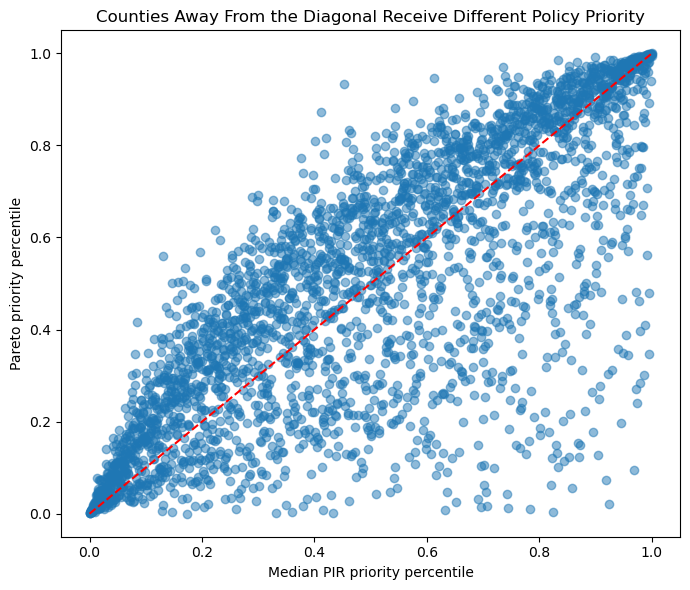

In [319]:
plt.figure(figsize=(7, 6))

plt.scatter(ranked_counties["median_pir_rank_pct"],ranked_counties["pareto_composite_rank_pct"], alpha=0.5)

# perfect agreement line
plt.plot([0, 1],[0, 1],linestyle="--", color='red')

plt.xlabel("Median PIR priority percentile")
plt.ylabel("Pareto priority percentile")
plt.title("Counties Away From the Diagonal Receive Different Policy Priority")

plt.tight_layout()
plt.show()

## Case Studies
The following examples will be selected based on the above analysis: 
* A consensus high-priority county; county in the top 10% under median PIR, Pareto, and CV
* A county ranked much higher by Pareto
* A county ranked much higher by CV

### A consensus high-priority county

In [320]:
# Case 1: county in the top 10% under median PIR, Pareto, and CV
consensus_candidates = (
    ranked_counties.loc[
        ranked_counties[
            "median_pir_rank_pct"
        ].le(0.10)
        & ranked_counties[
            "pareto_composite_rank_pct"
        ].le(0.10)
        & ranked_counties[
            "cv_temporal_rank_pct"
        ].le(0.10)
    ]
    .sort_values(
        "median_pir_rank"
    )
)

# use the strongest available consensus county
if not consensus_candidates.empty:
    consensus_case = (
        consensus_candidates
        .head(1)
        .copy()
    )
else:
    # fallback: require agreement between median PIR and Pareto
    consensus_case = (
        ranked_counties.loc[
            ranked_counties[
                "median_pir_rank_pct"
            ].le(0.10)
            & ranked_counties[
                "pareto_composite_rank_pct"
            ].le(0.10)
        ]
        .sort_values(
            "median_pir_rank"
        )
        .head(1)
        .copy()
    )

consensus_case[
    "case_type"
] = "Consensus high priority"

In [321]:
consensus_candidates

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff
283,08113,San Miguel County,CO,9,12.423144,11.422582,13.391794,0.094611,0.180538,10.180541,...,149.0,0.049518,16.0,16.0,160.0,160.0,166.0,166.0,141.0,141.0
1106,22027,Claiborne Parish,LA,9,6.835737,7.784188,2.975298,0.165439,0.317532,4.131699,...,2.0,0.000665,-4.0,4.0,-31.0,31.0,-31.0,31.0,-32.0,32.0
246,08037,Eagle County,CO,9,8.758165,7.659528,11.262268,0.096818,0.189995,7.339505,...,252.0,0.083749,56.0,56.0,108.0,108.0,94.0,94.0,217.0,217.0
280,08107,Routt County,CO,9,7.830893,7.477991,9.603445,0.087230,0.169092,6.578752,...,256.0,0.085078,82.0,82.0,234.0,234.0,215.0,215.0,219.0,219.0
540,16017,Bonner County,ID,9,7.696235,7.238308,8.884094,0.107124,0.205483,6.194822,...,128.0,0.042539,-12.0,12.0,30.0,30.0,31.0,31.0,84.0,84.0
1607,30067,Park County,MT,9,7.373652,6.992798,7.872744,0.088600,0.166505,6.136314,...,280.0,0.093054,101.0,101.0,195.0,195.0,236.0,236.0,231.0,231.0
2717,49019,Grand County,UT,9,7.490859,6.969089,8.040997,0.102344,0.193479,6.072393,...,157.0,0.052177,94.0,94.0,54.0,54.0,65.0,65.0,106.0,106.0
83,04005,Coconino County,AZ,9,7.178198,6.960944,8.324339,0.093387,0.176271,5.835053,...,238.0,0.079096,168.0,168.0,136.0,136.0,147.0,147.0,186.0,186.0
252,08049,Grand County,CO,9,7.155594,6.948882,8.332677,0.096695,0.182415,5.839317,...,276.0,0.091725,-17.0,17.0,90.0,90.0,112.0,112.0,222.0,222.0
2728,49043,Summit County,UT,9,7.800605,6.917263,9.612304,0.085352,0.168883,6.680365,...,287.0,0.095381,59.0,59.0,260.0,260.0,197.0,197.0,230.0,230.0


In [322]:
consensus_case

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff,case_type
283,08113,San Miguel County,CO,9,12.423144,11.422582,13.391794,0.094611,0.180538,10.180541,...,0.049518,16.0,16.0,160.0,160.0,166.0,166.0,141.0,141.0,Consensus high priority


#### Alternative Case 1: Counties in the top 10% under median PIR and Pareto composite

In [323]:
# Alternative Case 1: counties in the top 10% under median PIR and Pareto
consensus_candidates2 = (
    ranked_counties.loc[
        ranked_counties[
            "median_pir_rank_pct"
        ].le(0.10)
        & ranked_counties[
            "pareto_composite_rank_pct"
        ].le(0.10)
    ]
    .sort_values(
        "median_pir_rank"
    )
    .head(10)
    .copy()
)
consensus_candidates2

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff
1206,25019,Nantucket County,MA,9,21.446528,20.285054,25.000288,0.073162,0.145733,18.255671,...,424.0,0.140911,1.0,1.0,670.0,670.0,574.0,574.0,423.0,423.0
275,08097,Pitkin County,CO,9,16.715770,15.621689,19.645705,0.080168,0.154301,14.010648,...,418.0,0.138917,5.0,5.0,439.0,439.0,430.0,430.0,416.0,416.0
1826,36061,New York County,NY,9,14.905355,14.999891,10.880726,0.077375,0.150040,11.740183,...,265.0,0.088069,3.0,3.0,531.0,531.0,498.0,498.0,262.0,262.0
3068,56039,Teton County,WY,9,13.092836,12.887359,14.694273,0.083133,0.158449,10.932257,...,445.0,0.147890,1.0,1.0,353.0,353.0,369.0,369.0,441.0,441.0
1819,36047,Kings County,NY,9,11.834112,11.961997,10.763555,0.026871,0.051581,11.062122,...,2836.0,0.942506,6.0,6.0,2881.0,2881.0,2887.0,2887.0,2831.0,2831.0
1798,36005,Bronx County,NY,9,11.752029,11.917676,9.781410,0.057553,0.111082,9.762703,...,852.0,0.283151,2.0,2.0,1449.0,1449.0,1424.0,1424.0,846.0,846.0
1200,25007,Dukes County,MA,9,12.901039,11.860919,13.419572,0.072003,0.139652,11.375725,...,753.0,0.250249,12.0,12.0,711.0,711.0,685.0,685.0,746.0,746.0
283,08113,San Miguel County,CO,9,12.423144,11.422582,13.391794,0.094611,0.180538,10.180541,...,149.0,0.049518,16.0,16.0,160.0,160.0,166.0,166.0,141.0,141.0
207,06075,San Francisco County,CA,9,11.013288,11.058157,9.385245,0.037197,0.072274,10.154939,...,2525.0,0.839149,7.0,7.0,2514.0,2514.0,2497.0,2497.0,2516.0,2516.0
210,06081,San Mateo County,CA,9,10.502267,10.363694,9.858268,0.029625,0.057249,9.894673,...,2644.0,0.878697,13.0,13.0,2806.0,2806.0,2802.0,2802.0,2634.0,2634.0


In [324]:
consensus_candidates2.columns

Index(['FIPS', 'CountyName', 'StateAbbr', 'n_years', 'mean_pir', 'median_pir',
       'latest_pir', 'gini_temporal', 'cv_temporal', 'p10', 'p50', 'p90',
       'p90_p10', 'alpha', 'xmin', 'ks_distance', 'n_obs', 'n_tail',
       'tail_share', 'alpha_norm', 'xmin_norm', 'pareto_composite',
       'pareto_usable', 'mean_pir_rank', 'mean_pir_rank_pct',
       'median_pir_rank', 'median_pir_rank_pct', 'pareto_composite_rank',
       'pareto_composite_rank_pct', 'gini_temporal_rank',
       'gini_temporal_rank_pct', 'cv_temporal_rank', 'cv_temporal_rank_pct',
       'p90_p10_rank', 'p90_p10_rank_pct', 'pareto_composite_minus_pir_rank',
       'pareto_composite_pir_abs_rank_diff', 'gini_temporal_minus_pir_rank',
       'gini_temporal_pir_abs_rank_diff', 'cv_temporal_minus_pir_rank',
       'cv_temporal_pir_abs_rank_diff', 'p90_p10_minus_pir_rank',
       'p90_p10_pir_abs_rank_diff'],
      dtype='str')

In [325]:
consensus_candidates2[['FIPS', 'CountyName', 'StateAbbr', 'median_pir', 'pareto_composite', 'alpha_norm', 'xmin_norm', 'median_pir_rank', 'pareto_composite_rank']]

,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,alpha_norm,xmin_norm,median_pir_rank,pareto_composite_rank
1206,25019,Nantucket County,MA,20.285054,0.503076,0.006151,1.000000,1.0,2.0
275,08097,Pitkin County,CO,15.621689,0.378946,0.005256,0.752636,2.0,7.0
1826,36061,New York County,NY,14.999891,0.405478,0.015142,0.795814,3.0,6.0
3068,56039,Teton County,WY,12.887359,0.417955,0.041514,0.794397,4.0,5.0
1819,36047,Kings County,NY,11.961997,0.344075,0.053751,0.634398,5.0,11.0
1798,36005,Bronx County,NY,11.917676,0.365752,0.058549,0.672955,6.0,8.0
1200,25007,Dukes County,MA,11.860919,0.292429,0.005992,0.578865,7.0,19.0
283,08113,San Miguel County,CO,11.422582,0.266251,0.004199,0.528303,8.0,24.0
207,06075,San Francisco County,CA,11.058157,0.299544,0.027050,0.572038,9.0,16.0
210,06081,San Mateo County,CA,10.363694,0.267943,0.019514,0.516372,10.0,23.0


### A county ranked much higher by Pareto

In [326]:
# Case 2: the most negative rank difference is the county that Pareto moves toward higher priority most strongly
pareto_case = (
    ranked_counties
    .sort_values(
        "pareto_composite_minus_pir_rank",
        ascending=True
    )
    .head(1)
    .copy()
)

pareto_case["case_type"] = "Pareto assigns greater priority"

In [327]:
pareto_case

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff,case_type
664,17179,Tazewell County,IL,9,2.000955,2.036432,2.065738,0.022526,0.049272,1.852906,...,0.959455,-2721.0,2721.0,175.0,175.0,130.0,130.0,105.0,105.0,Pareto assigns greater priority


In [328]:
ranked_counties.sort_values(
        "pareto_composite_minus_pir_rank",
        ascending=True
    )

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff
664,17179,Tazewell County,IL,9,2.000955,2.036432,2.065738,0.022526,0.049272,1.852906,...,2887.0,0.959455,-2721.0,2721.0,175.0,175.0,130.0,130.0,105.0,105.0
2519,48111,Dallam County,TX,7,1.938792,1.794164,2.290555,0.090091,0.181619,1.597111,...,268.0,0.089066,-2625.0,2625.0,-2689.0,2689.0,-2745.0,2745.0,-2645.0,2645.0
2263,42123,Warren County,PA,9,1.955677,2.069698,2.190124,0.062714,0.121181,1.676663,...,1082.0,0.359588,-2545.0,2545.0,-1611.0,1611.0,-1636.0,1636.0,-1682.0,1682.0
448,13161,Jeff Davis County,GA,9,2.552464,2.372530,2.899039,0.057253,0.114386,2.281008,...,1514.0,0.503157,-2472.0,2472.0,-1009.0,1009.0,-1140.0,1140.0,-967.0,967.0
2048,39095,Lucas County,OH,9,2.302360,2.268613,2.554011,0.050211,0.096371,2.017212,...,1673.0,0.555999,-2416.0,2416.0,-722.0,722.0,-730.0,730.0,-910.0,910.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2721,49027,Millard County,UT,9,3.646579,3.603109,4.020767,0.094583,0.175554,2.911408,...,108.0,0.035892,1203.0,1203.0,-699.0,699.0,-661.0,661.0,-760.0,760.0
490,13247,Rockdale County,GA,9,3.408131,3.293100,4.187328,0.109825,0.206054,2.554965,...,39.0,0.012961,1227.0,1227.0,-1140.0,1140.0,-1134.0,1134.0,-1169.0,1169.0
2896,53027,Grays Harbor County,WA,9,4.405084,4.453605,5.328827,0.110594,0.209240,3.401107,...,67.0,0.022267,1293.0,1293.0,-328.0,328.0,-327.0,327.0,-325.0,325.0
990,21035,Calloway County,KY,9,3.267540,3.273600,3.766765,0.121254,0.227346,2.319888,...,13.0,0.004320,1390.0,1390.0,-1207.0,1207.0,-1201.0,1201.0,-1223.0,1223.0


### A county ranked much higher by CV

In [329]:
# Case 3: the most negative CV-minus-PIR difference is the county that CV moves toward higher priority most strongly
cv_case = (
    ranked_counties
    .sort_values(
        "cv_temporal_minus_pir_rank",
        ascending=True
    )
    .head(1)
    .copy()
)


cv_case["case_type"] = "CV assigns greater priority"

In [330]:
cv_case

,FIPS,CountyName,StateAbbr,n_years,mean_pir,median_pir,latest_pir,gini_temporal,cv_temporal,p10,...,p90_p10_rank_pct,pareto_composite_minus_pir_rank,pareto_composite_pir_abs_rank_diff,gini_temporal_minus_pir_rank,gini_temporal_pir_abs_rank_diff,cv_temporal_minus_pir_rank,cv_temporal_pir_abs_rank_diff,p90_p10_minus_pir_rank,p90_p10_pir_abs_rank_diff,case_type
880,20025,Clark County,KS,9,1.159642,1.054085,1.467955,0.100821,0.193872,0.941315,...,0.033234,0.0,0.0,-2899.0,2899.0,-2895.0,2895.0,-2909.0,2909.0,CV assigns greater priority


### Case studies summary

In [331]:
# combine the three cases
case_studies = pd.concat([consensus_case, pareto_case, cv_case], ignore_index=True)

# remove accidental duplicates in case the same county meets more than one criterion.
case_studies = (case_studies.drop_duplicates(subset="FIPS"))

case_studies[["case_type", "FIPS", "CountyName", "StateAbbr", "median_pir", "pareto_composite", "gini_temporal", "cv_temporal", "p90_p10", "alpha", "xmin", "n_tail"]]

,case_type,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,gini_temporal,cv_temporal,p90_p10,alpha,xmin,n_tail
0,Consensus high priority,08113,San Miguel County,CO,11.422582,0.266251,0.094611,0.180538,1.500346,6.091152,10.064629,9.0
1,Pareto assigns greater priority,17179,Tazewell County,IL,2.036432,0.198098,0.022526,0.049272,1.115955,242.393853,2.056469,4.0
2,CV assigns greater priority,20025,Clark County,KS,1.054085,0.001917,0.100821,0.193872,1.542057,5.827653,0.927349,9.0


#### Case studies plots

##### [HELPER FUNCTION]: `plot_county_case()`

In [332]:
def plot_county_case(panel, metric_table, fips):
    """
    This function plots the annual PIR for one case-study county.
    """

    # retrieve annual county data
    county_history = panel.loc[panel["FIPS"].eq(fips)].sort_values("Year")

    # retrieve the county's summary metrics
    county_metrics = metric_table.loc[metric_table["FIPS"].eq(fips)].iloc[0]

    plt.figure(figsize=(8, 4.5))

    # plot annual price-to-income ratio
    plt.plot(county_history["Year"], county_history["PIR"], marker="o")


    # add the county's median PIR
    plt.axhline(county_metrics["median_pir"], linestyle="--", label="2016-2024 median PIR", color="red")

    # add fitted xmin when it exists
    if pd.notna(county_metrics.get("xmin", np.nan)):
        plt.axhline(county_metrics["xmin"], linestyle=":", label="Pareto xmin", color="green")

    plt.xlabel("Year")
    plt.ylabel("Price-to-income ratio")

    plt.title(f"{county_metrics['CountyName']}, {county_metrics['StateAbbr']}: Annual Housing Affordability Pattern")

    plt.legend()
    plt.tight_layout()
    plt.show()

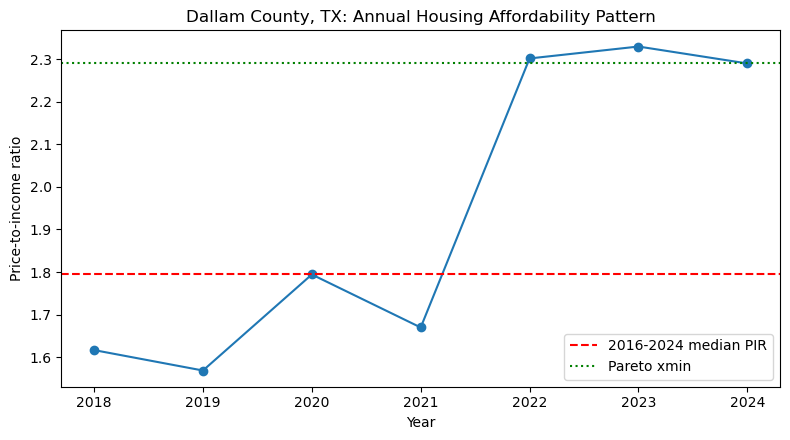

In [333]:
fip = '48111' # Dallam County, TX (Case Study 2 replacement)
x = housing_analysis_ext[housing_analysis_ext['FIPS'] == fip].copy()
y = ranked_counties[ranked_counties['FIPS'] == fip].copy()

plot_county_case(x,y,fip)

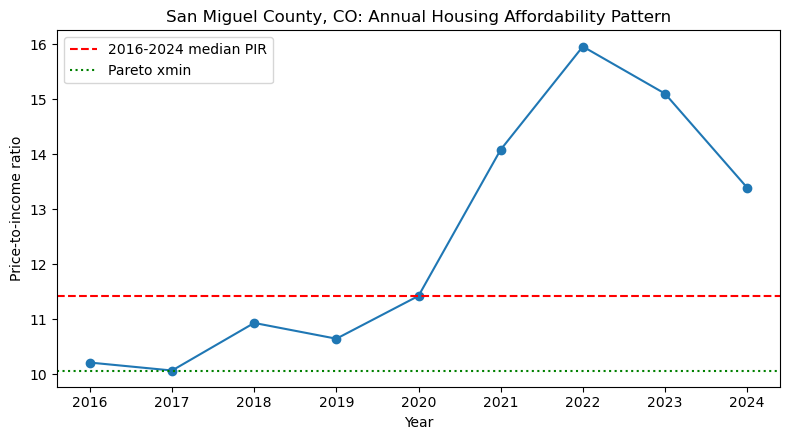

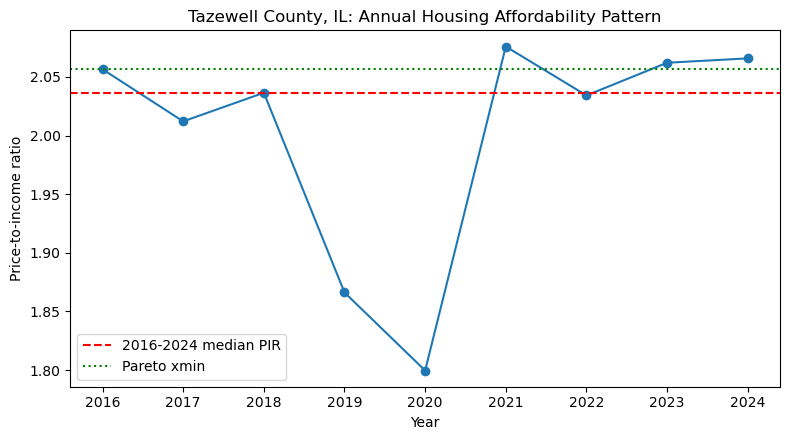

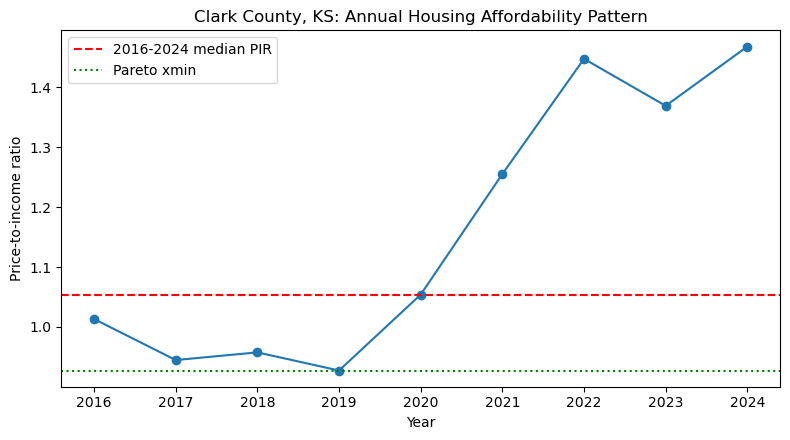

In [334]:
# Produce one separate chart for each selected county.
for fips in case_studies["FIPS"]:
    plot_county_case(housing_analysis_ext, ranked_counties, fips)

#### Consensus Candidate 2 Plots

In [335]:
consensus_examples = consensus_candidates2[['FIPS', 'CountyName', 'StateAbbr', 'median_pir', 'pareto_composite', 'alpha_norm', 'xmin_norm', 'median_pir_rank', 'pareto_composite_rank']].copy()
consensus_examples

,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,alpha_norm,xmin_norm,median_pir_rank,pareto_composite_rank
1206,25019,Nantucket County,MA,20.285054,0.503076,0.006151,1.000000,1.0,2.0
275,08097,Pitkin County,CO,15.621689,0.378946,0.005256,0.752636,2.0,7.0
1826,36061,New York County,NY,14.999891,0.405478,0.015142,0.795814,3.0,6.0
3068,56039,Teton County,WY,12.887359,0.417955,0.041514,0.794397,4.0,5.0
1819,36047,Kings County,NY,11.961997,0.344075,0.053751,0.634398,5.0,11.0
1798,36005,Bronx County,NY,11.917676,0.365752,0.058549,0.672955,6.0,8.0
1200,25007,Dukes County,MA,11.860919,0.292429,0.005992,0.578865,7.0,19.0
283,08113,San Miguel County,CO,11.422582,0.266251,0.004199,0.528303,8.0,24.0
207,06075,San Francisco County,CA,11.058157,0.299544,0.027050,0.572038,9.0,16.0
210,06081,San Mateo County,CA,10.363694,0.267943,0.019514,0.516372,10.0,23.0


In [336]:
consensus_examples[consensus_examples['FIPS'] == '08097']

,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,alpha_norm,xmin_norm,median_pir_rank,pareto_composite_rank
275,08097,Pitkin County,CO,15.621689,0.378946,0.005256,0.752636,2.0,7.0


In [337]:
consensus_examples[consensus_examples['FIPS'] == '06075']

,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,alpha_norm,xmin_norm,median_pir_rank,pareto_composite_rank
207,06075,San Francisco County,CA,11.058157,0.299544,0.02705,0.572038,9.0,16.0


In [338]:
consensus_examples[
    (consensus_examples['FIPS'] == '08097') |
    (consensus_examples['FIPS'] == '06075')
]

,FIPS,CountyName,StateAbbr,median_pir,pareto_composite,alpha_norm,xmin_norm,median_pir_rank,pareto_composite_rank
275,08097,Pitkin County,CO,15.621689,0.378946,0.005256,0.752636,2.0,7.0
207,06075,San Francisco County,CA,11.058157,0.299544,0.027050,0.572038,9.0,16.0


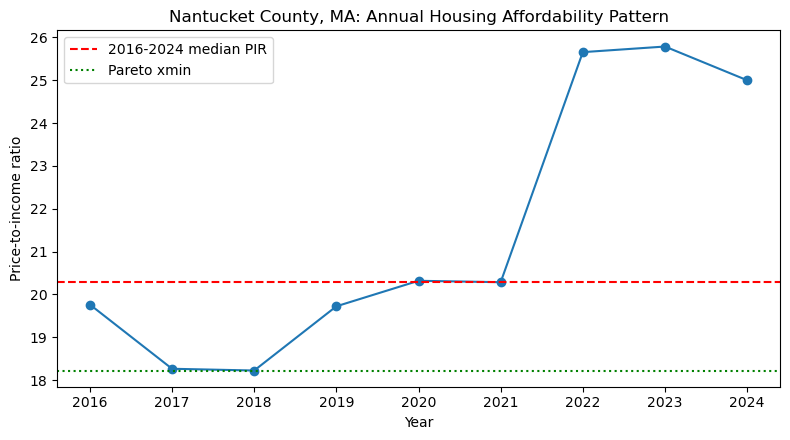

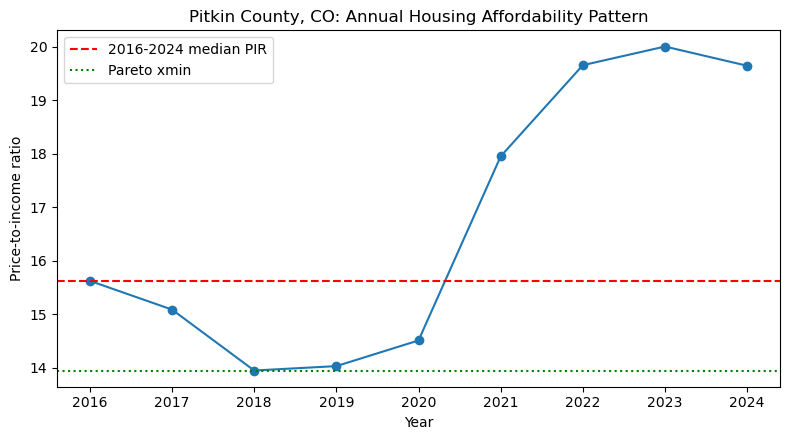

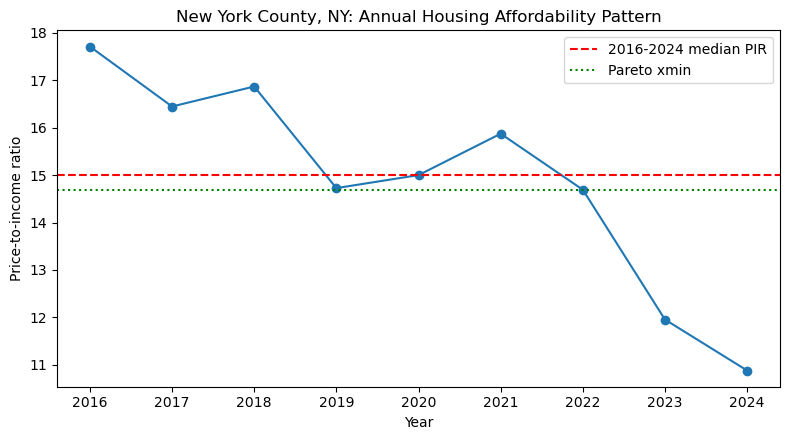

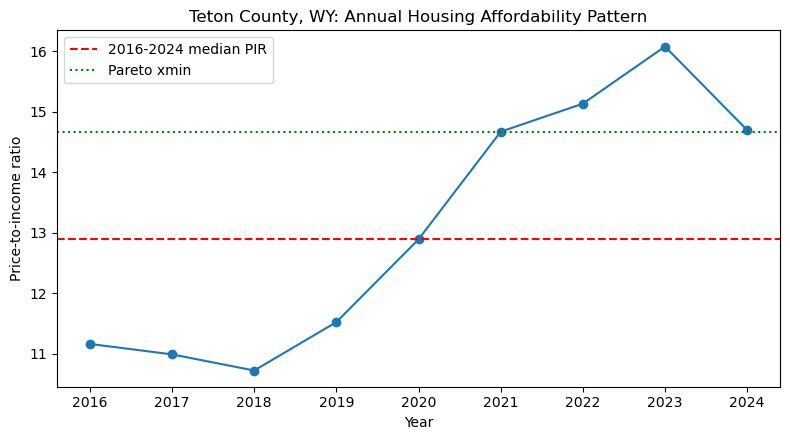

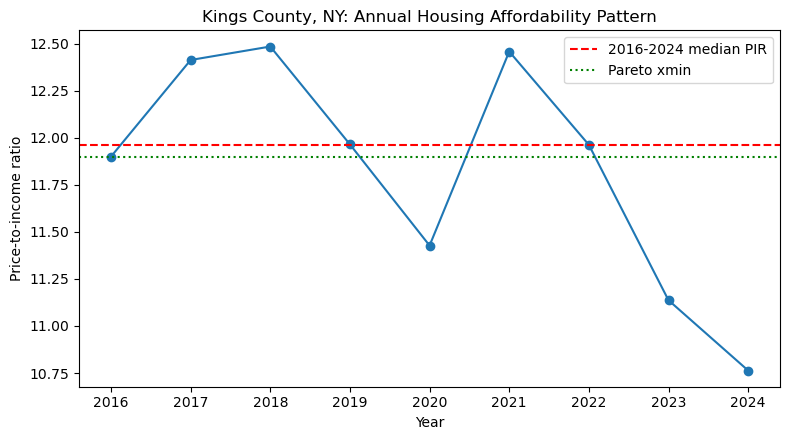

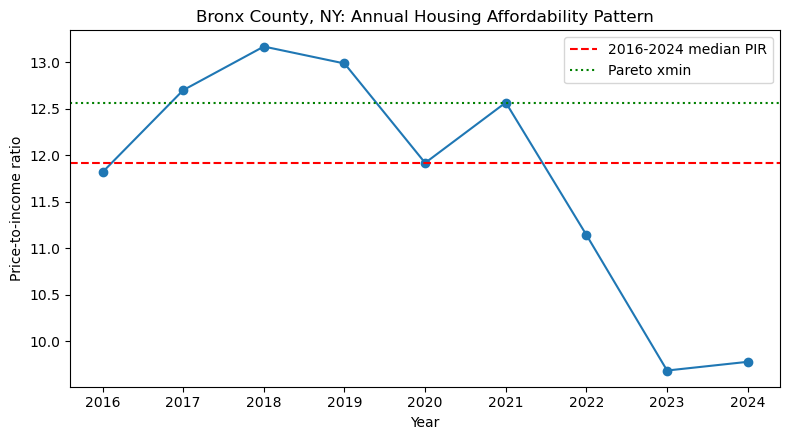

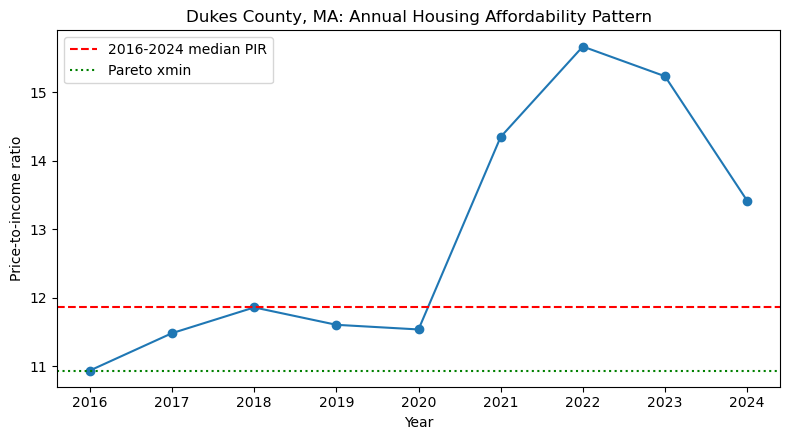

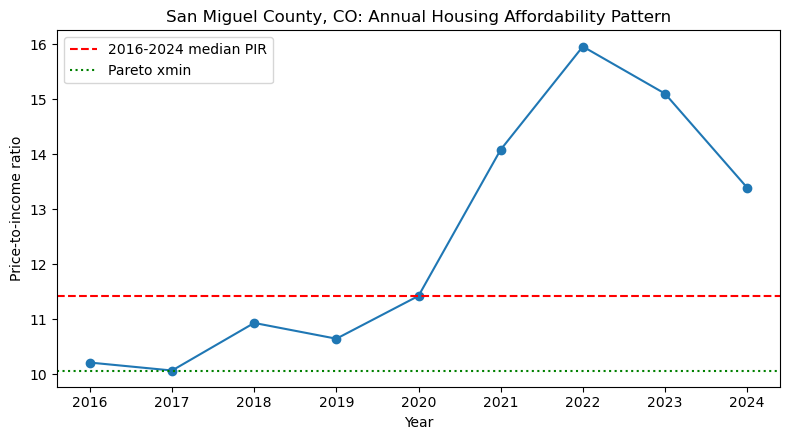

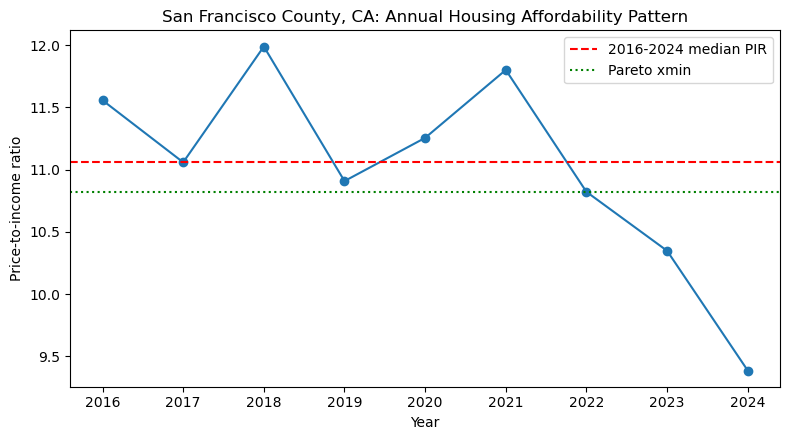

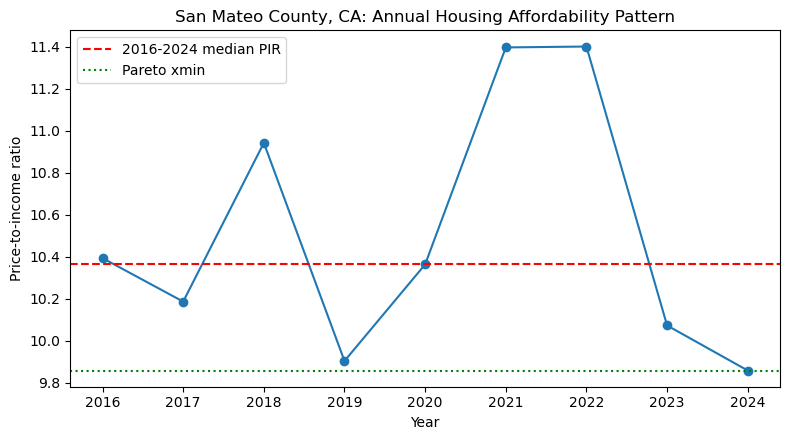

In [339]:
# Produce one separate chart for each selected county.
for fips in consensus_candidates2["FIPS"]:
    plot_county_case(housing_analysis_ext, ranked_counties, fips)

## Final metric scorecard

In [340]:
metric_scorecard = pd.DataFrame(
    {
        "Metric": [
            "Median PIR",
            "Pareto composite",
            "Temporal Gini",
            "Temporal CV",
            "P90/P10"
        ],

        "Primary purpose": [
            "Persistent affordability level",
            "Upper-tail affordability characteristics",
            "Unevenness across annual PIR values",
            "Relative annual PIR variability",
            "Spread between high- and low-PIR years"
        ],

        "Main strength": [
            "Easy to calculate and interpret",
            "Can identify tail patterns that PIR misses",
            "Established inequality measure",
            "Simple and interpretable variability measure",
            "Easy comparison of extreme annual values"
        ],

        "Main weakness": [
            "Does not measure instability or tail behavior",
            "Depends on small-sample Pareto fits and normalization",
            "Does not measure affordability level",
            "Does not measure affordability level",
            "Can be affected by extreme years"
        ],

        "Recommended use": [
            "Primary affordability-level baseline",
            "Supplementary tail-risk indicator",
            "Supporting validation measure",
            "Primary temporal-instability measure",
            "Supporting descriptive measure"
        ]
    }
)

metric_scorecard

,Metric,Primary purpose,Main strength,Main weakness,Recommended use
0,Median PIR,Persistent affordability level,Easy to calculate and interpret,Does not measure instability or tail behavior,Primary affordability-level baseline
1,Pareto composite,Upper-tail affordability characteristics,Can identify tail patterns that PIR misses,Depends on small-sample Pareto fits and normal...,Supplementary tail-risk indicator
2,Temporal Gini,Unevenness across annual PIR values,Established inequality measure,Does not measure affordability level,Supporting validation measure
3,Temporal CV,Relative annual PIR variability,Simple and interpretable variability measure,Does not measure affordability level,Primary temporal-instability measure
4,P90/P10,Spread between high- and low-PIR years,Easy comparison of extreme annual values,Can be affected by extreme years,Supporting descriptive measure


### Evidence summary

In [341]:
evidence_summary = pd.DataFrame(
    {
        "metric": validation_metrics,

        "coverage_pct": [
            coverage_table.loc[metric,"coverage_pct"]
            for metric in validation_metrics
        ],

        "correlation_with_median_pir": [
            spearman_correlation.loc[metric,"median_pir"]
            for metric in validation_metrics
        ],

        "strongest_other_correlation": [
            strongest_relationship.loc[metric,"strongest_other_correlation"]
            for metric in validation_metrics
        ],

        "most_similar_metric": [
            strongest_relationship.loc[metric,"most_similar_metric"]
            for metric in validation_metrics
        ]
    }
)

# add rank differences where they are applicable
rank_difference_lookup = rank_difference_summary.set_index("metric")["median_absolute_rank_difference"]

evidence_summary["median_absolute_rank_difference_from_pir"] = evidence_summary["metric"].map(rank_difference_lookup)

evidence_summary

,metric,coverage_pct,correlation_with_median_pir,strongest_other_correlation,most_similar_metric,median_absolute_rank_difference_from_pir
0,mean_pir,100.000000,0.991397,0.991397,median_pir,NaN
1,median_pir,100.000000,1.000000,0.991397,mean_pir,NaN
2,pareto_composite,97.949219,0.782020,0.782020,median_pir,310.0
3,gini_temporal,99.934896,0.112035,0.997101,cv_temporal,774.0
4,cv_temporal,99.934896,0.108831,0.997101,gini_temporal,769.0
5,p90_p10,99.934896,0.114122,0.982451,gini_temporal,773.0


In [342]:
evidence_summary.columns

Index(['metric', 'coverage_pct', 'correlation_with_median_pir',
       'strongest_other_correlation', 'most_similar_metric',
       'median_absolute_rank_difference_from_pir'],
      dtype='str')

In [343]:
evidence_summary[['metric', 'coverage_pct', 'correlation_with_median_pir', 'most_similar_metric','median_absolute_rank_difference_from_pir']]

,metric,coverage_pct,correlation_with_median_pir,most_similar_metric,median_absolute_rank_difference_from_pir
0,mean_pir,100.000000,0.991397,median_pir,NaN
1,median_pir,100.000000,1.000000,mean_pir,NaN
2,pareto_composite,97.949219,0.782020,median_pir,310.0
3,gini_temporal,99.934896,0.112035,cv_temporal,774.0
4,cv_temporal,99.934896,0.108831,gini_temporal,769.0
5,p90_p10,99.934896,0.114122,gini_temporal,773.0


## Save tables to CSV
This section saves the various tables from above to CSV for reference. 

In [344]:
# print("Exporting tables to CSV...")

# # tables created from import/merge
# zhvi_yearly.to_csv(export_data + f"zhvi_yearly_{formatted_time}.csv", index=False)
# saipe_merge.to_csv(export_data + f"saipe_merge_{formatted_time}.csv", index=False)

# # tables created from cleaning/EDA
# housing_df.to_csv(export_data + f"housing_df_{formatted_time}.csv", index=False)
# housing_analysis.to_csv(export_data + f"housing_analysis_{formatted_time}.csv", index=False)
# vp_results.to_csv(export_data + f"vp_results_{formatted_time}.csv", index=False)
# housing_analysis_ext.to_csv(export_data + f"housing_analysis_ext_{formatted_time}.csv", index=False)

# # validation tables
# metric_comparison.to_csv(export_data + f"metric_comparison_{formatted_time}.csv", index=False)
# ranked_counties.to_csv(export_data + f"ranked_counties_{formatted_time}.csv", index=False)
# descriptive_statistics.to_csv(export_data + f"validation_descriptive_statistics_{formatted_time}.csv", index=False)
# coverage_table.to_csv(export_data + f"metric_coverage_{formatted_time}.csv", index=False)
# spearman_correlation.to_csv(export_data + f"spearman_correlation_{formatted_time}.csv", index=False)
# rank_difference_summary.to_csv(export_data + f"rank_difference_summary_{formatted_time}.csv", index=False)
# largest_pareto_disagreements.to_csv(export_data + f"largest_pareto_disagreements_{formatted_time}.csv", index=False)
# case_studies.to_csv(export_data + f"validation_case_studies_{formatted_time}.csv", index=False)
# metric_scorecard.to_csv(export_data + f"metric_scorecard_{formatted_time}.csv", index=False)
# evidence_summary.to_csv(export_data + f"evidence_summary_{formatted_time}.csv", index=False)

# print("Export complete.")
# print(f"Files exported to the follwoing directory {export_data}")

# Version info

In [345]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import statsmodels
import powerlaw

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("statsmodels:", statsmodels.__version__)
print("powerlaw:", powerlaw.__version__)

Python: 3.14.2 | packaged by Anaconda, Inc. | (main, Dec 19 2025, 11:42:52) [Clang 20.1.8 ]
NumPy: 2.4.1
pandas: 3.0.0
matplotlib: 3.10.8
seaborn: 0.13.2
statsmodels: 0.14.6
powerlaw: 1.4.4


# _IL FINE_